# Physics-Informed Neural Networks (PINNs) for α-decay half-lives — four PDEs in one notebook

This notebook combines the four PINN notebooks **Royer-type**, **Denisov**, **Viola–Seaborg** and **Brown** into one workflow. The data, the Qα surrogate, the train/validation/test split, the network, the loss and the training routine are shared; only the physics (the PDE and the closed-form law it integrates to) differs between the models.

**Inputs (every model):** $Z_p,\; Z_d,\; \mu = 4A_d/A_p,\; Q_\alpha,\; \ell$ ($p$ = parent, $d$ = daughter) — **Target:** $\log_{10}T_{1/2}^{\alpha}$ (s).

| Model | PDE imposed in the loss | Closed-form law it integrates to | Residuals |
|---|---|---|---|
| **Royer-type** | $d\log_{10}T=\big(\tfrac{bA^{1/6}}{2\sqrt Z}+\tfrac{c}{\sqrt Q}-\tfrac{cZ}{2Q^{3/2}}\tfrac{\partial Q}{\partial Z}\big)dZ+\big(\tfrac{b\sqrt Z}{6A^{5/6}}-\tfrac{cZ}{2Q^{3/2}}\tfrac{\partial Q}{\partial A}\big)dA$ | $a+bA^{1/6}\sqrt Z+cZ/\sqrt Q$ | $dZ$, $dA$ |
| **Denisov** | three coefficients ($dZ$, $dA$, $d\ell$) of the Denisov total differential | $a-\dfrac{b\sqrt Z A^{1/6}}{\mu(A)}+\dfrac{cZ}{\sqrt Q}+\dfrac{d\sqrt{\ell(\ell+1)}A^{1/6}}{Q}+e(-1)^{\ell}$, $\mu(A)=4(A-4)/A$ | $dZ$, $dA$, $d\ell$ |
| **Viola–Seaborg** | $\dfrac{d\log_{10}T}{dZ}=\dfrac{a}{\sqrt Q}-\dfrac{aZ+b}{2Q^{3/2}}\dfrac{dQ}{dZ}+c$ | $\dfrac{aZ+b}{\sqrt Q}+cZ+d$ | $dZ$ |
| **Brown** | $\dfrac{d\log_{10}T}{dZ}=\dfrac{5.724}{Z^{0.4}\sqrt Q}-\dfrac{4.77Z^{0.6}}{Q^{3/2}}\dfrac{dQ}{dZ}$ | $\dfrac{k\,Z^{0.6}}{\sqrt Q}+d$ with $k=9.54$ ($0.6k=5.724$, $k/2=4.77$) | $dZ$ |

* Every network is $F_\theta=\text{closed-form law}(a,b,c,\dots)+\text{NN}(Z_p,Z_d,\mu,Q_\alpha,\ell)$; the coefficients are trainable and initialised by least squares. The PDE residuals (network total derivative minus PDE coefficient) are computed with `torch.autograd`; $\partial Q_\alpha/\partial Z$ and $\partial Q_\alpha/\partial A$ come from a smooth surrogate $\hat Q_\alpha(Z,A)$ fitted to all AME masses.
* Loss $=\lambda_\text{data}\,\text{MSE}+\lambda_\text{PDE}\times(\text{sum of the mean squared residuals of that PDE})$.
* **Denisov $d\ell$ equation:** the real part is imposed for $\ell\ge$ `L_PDE_MIN`; the imaginary term $i\pi e(-1)^\ell$ is realised through the parity term $e\cos(\pi\ell)$ of the baseline.

**Layout.** 1 configuration → 2 data → 3 Qα surrogate → 4 models and training → 5 results and graphs **for each model separately** → 6 **comparison of the four models** (test-RMSE table, bar chart, predicted-vs-experiment, residuals, and line diagrams of half-life vs neutron number N for all models together with the experiment) → 7 optional multi-seed comparison.

**Important for a fair comparison:** all four models are trained and tested on the *same* nuclei and the *same* split. The single setting `OUTLIER_CUTOFF` (data selection) therefore applies to all models. The uploaded single-model notebooks used different cut-offs (Royer 0.4, Denisov 0.7, Viola–Seaborg and Brown 1.0), which gives different data sets and RMSE values that cannot be compared with each other; here the default is 1.0 for all. Set it to 0.7 or 0.4 in `Config` to reproduce the "reduced RMSE" regime — note that this removes the hardest nuclei from the data set (see the check in section 6).

**All hyperparameters live in the `Config` cell and in `MODEL_SETTINGS`** (per-model overrides) — edit them there.

In [1]:
import os, re, math, copy, time
from dataclasses import dataclass
from typing import Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from dataclasses import replace

In [2]:
@dataclass
class Config:
    # ------------------------------------------------------------------ files
    AME_PATH: str = "ame_mass_data_csv.csv"
    NUBASE_PATH: str = "nubase_data_csv1.csv"

    # ------------------------------------- data selection (shared by all models)
    Z_MIN_EXCLUSIVE: int = 62            # keep parents with Z > 62  ("E > 62")
    EXCLUDE_EXTRAPOLATED: bool = True    # drop nuclides whose mass excess is a '#' (systematic) value
    ACCEPT_APPROX_BR: bool = True        # accept 'A~100' as well as 'A=xx' alpha branching
    ALPHA_BR_MIN_PERCENT: float = 1.0    # partial-half-life only reliable if alpha branch >= this (%)
    USE_SYSTEMATIC_SPINS: bool = True    # accept '#' (estimated) spin/parity when computing l
    DROP_UNKNOWN_SPIN: bool = True       # True: drop if l undefined; False: set l = 0
    OUTLIER_CUTOFF: Optional[float] = 1.0    # drop |logT - reference fit| >= cutoff (log10 units); None = no cut. Smaller = fewer, "easier" nuclei
    OUTLIER_REFERENCE: str = "denisov"       # law used for the cut: "denisov" | "royer" | "viola_seaborg" | "brown"
    OUTLIER_ITERS: int = 3

    # ------------------------------------------------------------ data split (identical for all models)
    TEST_SIZE: float = 0.15
    VAL_SIZE: float = 0.15
    SEED: int = 42

    # ------------------------------------------------- physics / PDE options
    USE_PHYSICS_BASELINE: bool = True    # F = closed-form law + CORR_SCALE * NN ;  False = pure NN (the PDE is then the only physics link)
    INIT_FROM_LSQ: bool = True           # initialise the law coefficients by least squares on the training set (False -> COEF_INIT)
    LEARN_PDE_COEFFS: bool = True        # law coefficients trainable
    CORR_SCALE: float = 1.0              # scale of the NN correction (baseline mode)
    INCLUDE_L_TERM: bool = True          # Denisov only: d*sqrt(l(l+1))A^(1/6)/Q term (and the dl-equation)
    INCLUDE_PARITY_TERM: bool = True     # Denisov only: e*(-1)^l term
    BROWN_EXPONENT: float = 0.6          # Brown only: exponent of Z
    W_PDE_Z: float = 1.0                 # relative weight of the dZ-equation
    W_PDE_A: float = 1.0                 # relative weight of the dA-equation (Royer, Denisov)
    W_PDE_L: float = 1.0                 # relative weight of the dl-equation (Denisov)
    L_PDE_MIN: int = 1                   # Denisov: dl-equation only for l >= L_PDE_MIN (l = 0 is singular)

    # ---------------------------------------------------------- network (defaults; overridden per model below)
    HIDDEN_LAYERS: Tuple[int, ...] = (64, 64, 64)
    ACTIVATION: str = "tanh"             # tanh | silu | gelu | softplus | sigmoid  (use smooth activations for the PDE)

    # ----------------------------------------------------------- training
    EPOCHS: int = 6000
    LR: float = 3e-3
    LR_PHYSICS: float = 1e-3             # learning rate of the law coefficients
    WEIGHT_DECAY: float = 1e-3           # applied to network weights only
    BATCH_SIZE: Optional[int] = None     # None = full batch
    LAMBDA_DATA: float = 1.0
    LAMBDA_PDE: float = 1.0              # global weight of the PDE residual loss (0 = plain NN; try 0.01 - 3)
    PDE_WARMUP_EPOCHS: int = 500         # linear ramp-up of LAMBDA_PDE
    GRAD_CLIP: Optional[float] = 5.0
    LR_FACTOR: float = 0.5               # ReduceLROnPlateau on validation RMSE
    LR_PATIENCE: int = 300
    MIN_LR: float = 1e-5
    EARLY_STOP_PATIENCE: int = 1000
    PRINT_EVERY: int = 1000

    # ------------------------------ Q_alpha(Z,A) surrogate (gives dQ/dZ, dQ/dA)
    SURR_Z_MIN: int = 60
    SURR_Q_MIN: float = 0.0              # train surrogate on nuclides with Q_alpha above this (MeV)
    SURR_USE_EXTRAPOLATED: bool = True
    SURR_HIDDEN: Tuple[int, ...] = (64, 64, 64)
    SURR_EPOCHS: int = 5000
    SURR_LR: float = 3e-3
    SURR_WEIGHT_DECAY: float = 0.0

    # ---------------------------------------------------------------- misc
    DTYPE: str = "float64"
    DEVICE: str = "cpu"
    RUN_MULTI_SEED: bool = False         # section 7: repeat all models over several splits / initialisations
    MULTI_SEEDS: Tuple[int, ...] = (0, 1, 2, 3, 4)

cfg = Config()

# models to train / compare (remove a name to skip a model) and their display names
MODELS = ["Royer", "Denisov", "ViolaSeaborg", "Brown"]
LABEL = {"Royer": "Royer-type", "Denisov": "Denisov", "ViolaSeaborg": "Viola-Seaborg", "Brown": "Brown"}
COLOR = {"Royer": "tab:blue", "Denisov": "tab:red", "ViolaSeaborg": "tab:green", "Brown": "tab:orange"}
MARK = {"Royer": "o", "Denisov": "s", "ViolaSeaborg": "^", "Brown": "D"}

# per-model overrides of Config (taken from the four single-model notebooks) - edit freely
MODEL_SETTINGS = {
    "Royer":        dict(HIDDEN_LAYERS=(128, 128, 128), LAMBDA_PDE=1.0, WEIGHT_DECAY=1e-3),
    "Denisov":      dict(HIDDEN_LAYERS=(64, 64, 64),    LAMBDA_PDE=1.0, WEIGHT_DECAY=1e-3),
    "ViolaSeaborg": dict(HIDDEN_LAYERS=(64, 64, 64),    LAMBDA_PDE=1.0, WEIGHT_DECAY=1e-3),
    "Brown":        dict(HIDDEN_LAYERS=(128, 128, 128), LAMBDA_PDE=1.0, WEIGHT_DECAY=1e-3),
}
# initial law coefficients, used only when INIT_FROM_LSQ = False
COEF_INIT = {
    "Royer":        dict(a=-25.31, b=-1.1629, c=1.5864),
    "Denisov":      dict(a=-25.3, b=4.4, c=1.59, d=0.0, e=0.0),
    "ViolaSeaborg": dict(a=1.66, b=-8.5, c=-0.20, d=-33.9),
    "Brown":        dict(k=9.54, d=-51.37),
}

def model_cfg(name):
    return replace(cfg, **MODEL_SETTINGS.get(name, {}))

torch.set_default_dtype(getattr(torch, cfg.DTYPE))
DT = getattr(torch, cfg.DTYPE)
device = torch.device(cfg.DEVICE)
print(cfg)
for m in MODELS:
    print(f"{LABEL[m]:14s}", MODEL_SETTINGS.get(m, {}))

Config(AME_PATH='ame_mass_data_csv.csv', NUBASE_PATH='nubase_data_csv1.csv', Z_MIN_EXCLUSIVE=62, EXCLUDE_EXTRAPOLATED=True, ACCEPT_APPROX_BR=True, ALPHA_BR_MIN_PERCENT=1.0, USE_SYSTEMATIC_SPINS=True, DROP_UNKNOWN_SPIN=True, OUTLIER_CUTOFF=1.0, OUTLIER_REFERENCE='denisov', OUTLIER_ITERS=3, TEST_SIZE=0.15, VAL_SIZE=0.15, SEED=42, USE_PHYSICS_BASELINE=True, INIT_FROM_LSQ=True, LEARN_PDE_COEFFS=True, CORR_SCALE=1.0, INCLUDE_L_TERM=True, INCLUDE_PARITY_TERM=True, BROWN_EXPONENT=0.6, W_PDE_Z=1.0, W_PDE_A=1.0, W_PDE_L=1.0, L_PDE_MIN=1, HIDDEN_LAYERS=(64, 64, 64), ACTIVATION='tanh', EPOCHS=6000, LR=0.003, LR_PHYSICS=0.001, WEIGHT_DECAY=0.001, BATCH_SIZE=None, LAMBDA_DATA=1.0, LAMBDA_PDE=1.0, PDE_WARMUP_EPOCHS=500, GRAD_CLIP=5.0, LR_FACTOR=0.5, LR_PATIENCE=300, MIN_LR=1e-05, EARLY_STOP_PATIENCE=1000, PRINT_EVERY=1000, SURR_Z_MIN=60, SURR_Q_MIN=0.0, SURR_USE_EXTRAPOLATED=True, SURR_HIDDEN=(64, 64, 64), SURR_EPOCHS=5000, SURR_LR=0.003, SURR_WEIGHT_DECAY=0.0, DTYPE='float64', DEVICE='cpu', RUN_MUL

## 2. Load AME + NUBASE and build the data set (shared by all models)

1. NUBASE **ground states** only (isomer digit = 0) with **Z > 62**.
2. α branch listed in the decay-mode string (`A=xx` or `A~xx`); partial α half-life $=T_{1/2}\cdot100/\text{BR}_\alpha$.
3. Parent and daughter masses in AME → $Q_\alpha=\Delta M_p-\Delta M_d-\Delta M_{^4\mathrm{He}}$; keep **$Q_\alpha>0$** (α-decay eligible).
4. $\ell_{\min}$ from the ground-state spin/parity of parent and daughter.
5. Optional robust outlier cut against a least-squares reference law (`OUTLIER_CUTOFF`, `OUTLIER_REFERENCE`).

In [3]:
UNIT_TO_SEC = {"ys":1e-24,"zs":1e-21,"as":1e-18,"fs":1e-15,"ps":1e-12,"ns":1e-9,"us":1e-6,"ms":1e-3,
               "s":1.0,"m":60.0,"h":3600.0,"d":86400.0,"y":365.25*86400.0,
               "ky":1e3*365.25*86400.0,"My":1e6*365.25*86400.0,"Gy":1e9*365.25*86400.0,
               "Ty":1e12*365.25*86400.0,"Py":1e15*365.25*86400.0,"Ey":1e18*365.25*86400.0,
               "Zy":1e21*365.25*86400.0,"Yy":1e24*365.25*86400.0}

def find_file(path):
    for p in (path, os.path.join("/mnt/user-data/uploads", os.path.basename(path))):
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{path} not found - put the CSV next to the notebook or edit cfg.*_PATH")

def load_ame(path):
    df = pd.read_csv(find_file(path), dtype=str)
    me = df["Mass_Excess_keV"].astype(str)
    df["Z"] = df["Z"].astype(int); df["A"] = df["A"].astype(int)
    df["extrap"] = me.str.contains("#")
    df["ME_keV"] = pd.to_numeric(me.str.replace("#", "", regex=False).str.strip(), errors="coerce")
    return df.dropna(subset=["ME_keV"]).reset_index(drop=True)

def load_nubase(path):
    df = pd.read_csv(find_file(path), dtype=str)          # dtype=str keeps leading zeros of 'Atomic_Number_Isomer'
    df["A"]   = df["Mass_Number"].astype(int)
    df["Z"]   = df["Atomic_Number_Isomer"].str[:3].astype(int)
    df["iso"] = df["Atomic_Number_Isomer"].str[3].astype(int)   # 0 = ground state
    return df

def parse_alpha_branch(s, accept_approx=True):
    '''alpha branching (%) from e.g. 'B+=2.1;A=97.9 3' or 'A~100'. NaN if unknown ('A ?', 'A<..').'''
    if not isinstance(s, str):
        return np.nan
    for tok in s.split(";"):
        m = re.match(r"^A\s*([=~])\s*([0-9.]+(?:[eE][-+]?\d+)?)", tok.strip())
        if m and (m.group(1) == "=" or accept_approx):
            return float(m.group(2))
    return np.nan

def half_life_seconds(val, unit):
    if not isinstance(val, str) or not isinstance(unit, str):
        return np.nan
    v = val.strip()
    if not re.fullmatch(r"\d+(\.\d+)?([eE][-+]?\d+)?", v):       # rejects '#', '~', '<', '>', 'stbl'
        return np.nan
    return float(v) * UNIT_TO_SEC.get(unit.strip(), np.nan)

def parse_spin(s, accept_systematic=True):
    '''-> (J, parity) ; parity = +1/-1/None.  First candidate is used for ambiguous assignments.'''
    if not isinstance(s, str):
        return None
    s0 = s.split("T=")[0]
    if "#" in s0 and not accept_systematic:
        return None
    t = s0.replace("#", "").replace("*", "").replace("frg", "").strip()
    if not t:
        return None
    first = re.split(r"[,;]| to | or |\s", t)[0]
    m = re.search(r"(\d+)(?:/(\d+))?", first)
    if not m:
        return None
    J = int(m.group(1)) / (int(m.group(2)) if m.group(2) else 1)
    par = None
    if "+" in first:   par = +1
    elif "-" in first: par = -1
    else:
        mp = re.search(r"\)\s*([+-])", t)                # e.g. '(3,4)+'
        if mp: par = +1 if mp.group(1) == "+" else -1
    return J, par

def l_min(sp, sd):
    '''minimum alpha angular momentum: |Jp-Jd| <= l <= Jp+Jd and (-1)^l = pi_p * pi_d.'''
    if sp is None or sd is None:
        return np.nan
    (Jp, pp), (Jd, pd_) = sp, sd
    dj = abs(Jp - Jd)
    if abs(dj - round(dj)) > 1e-9:
        return np.nan
    dj = int(round(dj))
    if pp is None or pd_ is None:
        return float(dj)
    l = dj if (-1) ** dj == pp * pd_ else dj + 1
    if l > Jp + Jd:                                        # inconsistent (uncertain) assignment
        l = dj
    return float(l)

# ---- numpy versions of the four closed-form laws (used for LSQ initialisation, closed-form reference and the outlier cut) ----
def mu_of_A(A):            # mu(A) = 4 (A-4)/A = 4 Ad / Ap
    return 4.0 * (A - 4.0) / A

def sqrt_ll(l):            # sqrt(l(l+1)), exactly 0 for l = 0
    return np.sqrt(l * (l + 1.0))

def royer_design(Z, A, Q):
    """columns of [a, b, c] in  logT = a + b A^(1/6) sqrt(Z) + c Z/sqrt(Q)"""
    Z, A, Q = (np.asarray(v, float) for v in (Z, A, Q))
    return np.c_[np.ones(len(Z)), A ** (1 / 6) * np.sqrt(Z), Z / np.sqrt(Q)]

def denisov_design(Z, A, Q, l):
    """columns of [a, b, c, d, e] in  logT = a - b sqrt(Z) A^(1/6)/mu + c Z/sqrt(Q) + d sqrt(l(l+1)) A^(1/6)/Q + e (-1)^l"""
    Z, A, Q, l = (np.asarray(v, float) for v in (Z, A, Q, l))
    return np.c_[np.ones(len(Z)),
                 -np.sqrt(Z) * A ** (1 / 6) / mu_of_A(A),
                 Z / np.sqrt(Q),
                 sqrt_ll(l) * A ** (1 / 6) / Q,
                 np.cos(np.pi * l)]

def vs_design(Z, Q):
    """columns of [a, b, c, d] in  logT = (aZ + b)/sqrt(Q) + c Z + d"""
    Z, Q = np.asarray(Z, float), np.asarray(Q, float)
    return np.c_[Z / np.sqrt(Q), 1.0 / np.sqrt(Q), Z, np.ones(len(Z))]

def brown_design(Z, Q, p=0.6):
    """columns of [k, d] in  logT = k Z^p / sqrt(Q) + d"""
    Z, Q = np.asarray(Z, float), np.asarray(Q, float)
    return np.c_[Z ** p / np.sqrt(Q), np.ones(len(Z))]

def active_columns(cfg):   # Denisov columns that are switched on
    cols = [0, 1, 2]
    if cfg.INCLUDE_L_TERM:      cols.append(3)
    if cfg.INCLUDE_PARITY_TERM: cols.append(4)
    return cols

def ref_design(cfg, f):
    """design matrix of the reference law used for the outlier cut"""
    r = cfg.OUTLIER_REFERENCE
    if r == "denisov":      return denisov_design(f.Z, f.A, f.Q, f.l)[:, active_columns(cfg)]
    if r == "royer":        return royer_design(f.Z, f.A, f.Q)
    if r == "viola_seaborg": return vs_design(f.Z, f.Q)
    if r == "brown":        return brown_design(f.Z, f.Q, cfg.BROWN_EXPONENT)
    raise ValueError(r)

def build_dataset(cfg):
    ame, nub = load_ame(cfg.AME_PATH), load_nubase(cfg.NUBASE_PATH)
    ame_d = {(z, a): (m, e) for z, a, m, e in zip(ame.Z, ame.A, ame.ME_keV, ame.extrap)}
    he4 = ame_d[(2, 4)][0]                                  # 2424.91587 keV
    gs = nub[nub.iso == 0].copy()                           # ground states only
    gs_d = {(z, a): r for z, a, r in zip(gs.Z, gs.A, gs.itertuples(index=False))}

    par = gs[gs.Z > cfg.Z_MIN_EXCLUSIVE].copy()
    funnel = [(f"ground-state nuclides with Z > {cfg.Z_MIN_EXCLUSIVE}", len(par))]
    par["BR"] = par["Decay_Modes_Intensities"].map(lambda s: parse_alpha_branch(s, cfg.ACCEPT_APPROX_BR))
    par = par[par.BR.notna() & (par.BR > 0)];               funnel.append(("alpha branch reported (A= / A~)", len(par)))
    par = par[par.BR >= cfg.ALPHA_BR_MIN_PERCENT];          funnel.append((f"alpha branching >= {cfg.ALPHA_BR_MIN_PERCENT}%", len(par)))
    par["T_tot_s"] = [half_life_seconds(v, u) for v, u in zip(par.Half_life, par.Half_life_unit)]
    par = par[par.T_tot_s.notna() & (par.T_tot_s > 0)];     funnel.append(("measured numeric half-life", len(par)))
    ok = [((z, a) in ame_d) and ((z - 2, a - 4) in ame_d) and ((z - 2, a - 4) in gs_d) for z, a in zip(par.Z, par.A)]
    par = par[ok].copy();                                   funnel.append(("parent & daughter found in AME / NUBASE", len(par)))
    par["extrap"] = [ame_d[(z, a)][1] or ame_d[(z - 2, a - 4)][1] for z, a in zip(par.Z, par.A)]
    if cfg.EXCLUDE_EXTRAPOLATED:
        par = par[~par.extrap];                             funnel.append(("no extrapolated (#) mass excess", len(par)))
    par["Q"] = [(ame_d[(z, a)][0] - ame_d[(z - 2, a - 4)][0] - he4) / 1000.0 for z, a in zip(par.Z, par.A)]   # MeV
    par = par[par.Q > 0];                                   funnel.append(("Q_alpha > 0  (alpha decay energetically allowed)", len(par)))
    par["logT"] = np.log10(par.T_tot_s * 100.0 / par.BR)    # partial alpha half-life
    sp = [parse_spin(s, cfg.USE_SYSTEMATIC_SPINS) for s in par.Spin_Parity]
    sd = [parse_spin(gs_d[(z - 2, a - 4)].Spin_Parity, cfg.USE_SYSTEMATIC_SPINS) for z, a in zip(par.Z, par.A)]
    par["l"] = [l_min(p, d) for p, d in zip(sp, sd)]
    if cfg.DROP_UNKNOWN_SPIN:
        par = par[par.l.notna()];                           funnel.append(("spin/parity known for parent & daughter (l defined)", len(par)))
    else:
        par["l"] = par.l.fillna(0.0)

    out = pd.DataFrame({"name": par.A_El.values, "Z": par.Z.values, "A": par.A.values,
                        "Zd": par.Z.values - 2, "Ad": par.A.values - 4,
                        "Q": par.Q.values, "l": par.l.values, "BR": par.BR.values, "logT": par.logT.values})
    out["mu"] = 4.0 * out.Ad / out.A                        # mu = 4 * Ad / Ap
    out = out.reset_index(drop=True)

    if cfg.OUTLIER_CUTOFF is not None:                      # robust reference fit (OUTLIER_REFERENCE law), then cut
        keep = np.ones(len(out), bool)
        X, y = ref_design(cfg, out), out.logT.values
        for _ in range(cfg.OUTLIER_ITERS):
            c, *_ = np.linalg.lstsq(X[keep], y[keep], rcond=None)
            keep = np.abs(y - X @ c) < cfg.OUTLIER_CUTOFF
        out = out[keep].reset_index(drop=True)
        funnel.append((f"outlier cut |dlogT| < {cfg.OUTLIER_CUTOFF}", len(out)))
    return out, funnel, ame

df, funnel, ame = build_dataset(cfg)
print(pd.DataFrame(funnel, columns=["selection step", "n nuclides"]).to_string(index=False))
print()
display(df[["name", "Z", "A", "Zd", "mu", "Q", "l", "BR", "logT"]].head(10))
print(df[["Z", "A", "Q", "l", "logT"]].describe().T)

                                     selection step  n nuclides
                  ground-state nuclides with Z > 62        1603
                    alpha branch reported (A= / A~)         659
                            alpha branching >= 1.0%         561
                         measured numeric half-life         558
            parent & daughter found in AME / NUBASE         558
                    no extrapolated (#) mass excess         422
   Q_alpha > 0  (alpha decay energetically allowed)         422
spin/parity known for parent & daughter (l defined)         418
                          outlier cut |dlogT| < 1.0         386



,name,Z,A,Zd,mu,Q,l,BR,logT
0,148Gd,64,148,62,3.891892,3.271291,0.0,100.0,9.352193
1,149Tb,65,149,63,3.892617,4.077969,2.0,16.7,4.948272
2,150Gd,64,150,62,3.893333,2.807393,0.0,100.0,13.751957
3,150Dy,66,150,64,3.893333,4.351289,0.0,33.6,3.107331
4,151Eu,63,151,61,3.894040,1.963970,2.0,100.0,26.161862
5,151Dy,66,151,64,3.894040,4.179624,0.0,5.6,4.282816
6,152Gd,64,152,62,3.894737,2.203847,0.0,100.0,21.532528
7,152Ho,67,152,65,3.894737,4.507395,0.0,12.0,3.129797
8,152Er,68,152,66,3.894737,4.934263,0.0,90.0,1.058595
9,153Er,68,153,66,3.895425,4.802392,0.0,53.0,1.845098


      count        mean        std         min         25%         50%  \
Z     386.0   87.090674   8.393230   63.000000   83.000000   87.000000   
A     386.0  209.253886  27.716708  148.000000  190.000000  212.000000   
Q     386.0    6.972628   1.461084    1.963970    6.118193    6.922352   
l     386.0    0.704663   1.371634    0.000000    0.000000    0.000000   
logT  386.0    1.698154   5.342571   -7.251812   -1.497242    0.680886   

             75%         max  
Z      91.750000  110.000000  
A     225.000000  270.000000  
Q       7.851725   11.116993  
l       1.000000    5.000000  
logT    3.322933   26.802300  


## 3. $\partial Q_\alpha/\partial Z$ and $\partial Q_\alpha/\partial A$ (shared)

The PDEs need the derivatives of $Q_\alpha$ with respect to $Z$ and $A$. They are obtained by automatic differentiation of a small network fitted to the AME $Q_\alpha$ table (all nuclides with $Z\ge$ `SURR_Z_MIN` and $Q_\alpha>$ `SURR_Q_MIN`). The surrogate is frozen afterwards.

In [4]:
class QSurrogate(nn.Module):
    def __init__(self, hidden, mean, std, q_mean, q_std):
        super().__init__()
        layers, d = [], 2
        for h in hidden:
            layers += [nn.Linear(d, h), nn.Tanh()]; d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)
        self.register_buffer("mean", mean); self.register_buffer("std", std)
        self.q_mean, self.q_std = float(q_mean), float(q_std)
    def forward(self, Z, A):
        x = (torch.stack([Z, A], dim=1) - self.mean) / self.std
        return self.net(x).squeeze(-1) * self.q_std + self.q_mean

def train_q_surrogate(ame_df, cfg, seed=0):
    d = {(z, a): (m, e) for z, a, m, e in zip(ame_df.Z, ame_df.A, ame_df.ME_keV, ame_df.extrap)}
    he4 = d[(2, 4)][0]
    rows = []
    for (z, a), (m, e) in d.items():
        if z < cfg.SURR_Z_MIN or (z - 2, a - 4) not in d:
            continue
        md_, ed_ = d[(z - 2, a - 4)]
        if (e or ed_) and not cfg.SURR_USE_EXTRAPOLATED:
            continue
        q = (m - md_ - he4) / 1000.0
        if q > cfg.SURR_Q_MIN:
            rows.append((z, a, q))
    S = np.array(rows, dtype=float)
    X = torch.tensor(S[:, :2], dtype=DT, device=device); y = torch.tensor(S[:, 2], dtype=DT, device=device)
    torch.manual_seed(seed)
    model = QSurrogate(cfg.SURR_HIDDEN, X.mean(0), X.std(0), y.mean().item(), y.std().item()).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.SURR_LR, weight_decay=cfg.SURR_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.SURR_EPOCHS, eta_min=cfg.SURR_LR * 0.01)
    for ep in range(cfg.SURR_EPOCHS):
        opt.zero_grad()
        loss = torch.mean((model(X[:, 0], X[:, 1]) - y) ** 2)
        loss.backward(); opt.step(); sched.step()
    with torch.no_grad():
        rmse = torch.sqrt(torch.mean((model(X[:, 0], X[:, 1]) - y) ** 2)).item()
    print(f"Q surrogate: {len(S)} nuclides, fit RMSE = {rmse:.3f} MeV")
    for p in model.parameters():
        p.requires_grad_(False)
    return model

def q_gradients(model, Z, A):
    Z = Z.detach().clone().requires_grad_(True); A = A.detach().clone().requires_grad_(True)
    with torch.enable_grad():
        q = model(Z, A)
        gZ, gA = torch.autograd.grad(q.sum(), (Z, A))
    return gZ.detach(), gA.detach()

q_model = train_q_surrogate(ame, cfg)
_Z = torch.tensor(df.Z.values, dtype=DT, device=device); _A = torch.tensor(df.A.values, dtype=DT, device=device)
_dQdZ, _dQdA = q_gradients(q_model, _Z, _A)
df["dQdZ"] = _dQdZ.cpu().numpy(); df["dQdA"] = _dQdA.cpu().numpy()
print(df[["dQdZ", "dQdA"]].describe().T)

Q surrogate: 1470 nuclides, fit RMSE = 0.299 MeV
      count      mean       std       min       25%       50%       75%  \
dQdZ  386.0  0.549356  0.476796 -1.970914  0.456223  0.573061  0.665243   
dQdA  386.0 -0.121455  0.387729 -0.665709 -0.244033 -0.142844 -0.105639   

           max  
dQdZ  3.430429  
dQdA  2.343861  


## 4. The four PINN models, training routine and training

All four models share `BasePINN` (input standardisation, network, forward pass, loss). A model class only defines (i) its closed-form **physics baseline**, (ii) its **PDE residuals** and (iii) how its coefficients are initialised by least squares. Training uses Adam, a ReduceLROnPlateau scheduler and early stopping on validation RMSE.

In [5]:
ACTS = {"tanh": nn.Tanh, "silu": nn.SiLU, "gelu": nn.GELU, "softplus": nn.Softplus, "sigmoid": nn.Sigmoid}

def make_mlp(n_in, hidden, act, n_out=1):
    layers, d = [], n_in
    for h in hidden:
        lin = nn.Linear(d, h); nn.init.xavier_normal_(lin.weight); nn.init.zeros_(lin.bias)
        layers += [lin, ACTS[act]()]; d = h
    last = nn.Linear(d, n_out); nn.init.xavier_normal_(last.weight); nn.init.zeros_(last.bias)
    with torch.no_grad():
        last.weight.mul_(0.1)
    layers.append(last)
    return nn.Sequential(*layers)

def mu_fn(A):
    return 4.0 * (A - 4.0) / A                       # mu(A) = 4 Ad / Ap

def dmu_fn(A):
    return 16.0 / A ** 2                             # mu'(A)

def safe_S(l):
    # S = sqrt(l(l+1)); exactly 0 for l = 0 and finite gradients everywhere. returns (S, mask l>0, S with 1 where l=0)
    pos = l > 0.5
    ll = torch.where(pos, l * (l + 1.0), torch.ones_like(l))
    s1 = torch.sqrt(ll)
    return s1 * pos.to(l.dtype), pos, s1

def feature_matrix(Z, A, Q, l):
    # input features [Zp, Zd, mu, Qa, l] ; mu = 4*Ad/Ap ; differentiable w.r.t. Z, A, Q, l.
    return torch.stack([Z, Z - 2.0, mu_fn(A), Q, l], dim=1)

def _param(v, train):
    return nn.Parameter(torch.tensor(float(v)), requires_grad=bool(train))

class BasePINN(nn.Module):
    NAME = "base"
    COEFS = ()                                       # names of the law coefficients
    LSQ_NAMES = ()                                   # coefficient names matching the LSQ design columns

    def __init__(self, cfg, x_mean, x_std, y_mean, y_std, coef_init):
        super().__init__()
        self.cfg = cfg
        self.register_buffer("x_mean", x_mean); self.register_buffer("x_std", x_std)
        self.y_mean, self.y_std = float(y_mean), float(y_std)
        self.net = make_mlp(5, cfg.HIDDEN_LAYERS, cfg.ACTIVATION)
        self._build(coef_init)

    def phys_params(self):
        return [getattr(self, n) for n in self.COEFS]

    def coef_dict(self):
        return {n: float(getattr(self, n).item()) for n in self.COEFS}

    def forward(self, Z, A, Q, l):
        x = (feature_matrix(Z, A, Q, l) - self.x_mean) / self.x_std
        nn_out = self.net(x).squeeze(-1)
        if self.cfg.USE_PHYSICS_BASELINE:
            return self.physics_base(Z, A, Q, l) + self.cfg.CORR_SCALE * nn_out
        return self.y_mean + self.y_std * nn_out

    def _grads(self, Z, A, Q, l, wrt):
        # autograd of the network output w.r.t. the requested inputs (create_graph for the PDE loss)
        v = {"Z": Z, "A": A, "Q": Q, "l": l}
        for k in wrt:
            v[k] = v[k].detach().clone().requires_grad_(True)
        with torch.enable_grad():
            f = self.forward(v["Z"], v["A"], v["Q"], v["l"])
            g = torch.autograd.grad(f.sum(), [v[k] for k in wrt], create_graph=True)
        return v, dict(zip(wrt, g))

    def pde_loss(self, batch):
        # weighted sum of the mean squared PDE residuals + RMS of each residual (for printing)
        cfg = self.cfg
        res = self.pde_residuals(batch["Z"], batch["A"], batch["Q"], batch["l"], batch["dQdZ"], batch["dQdA"])
        w = {"Z": cfg.W_PDE_Z, "A": cfg.W_PDE_A, "l": cfg.W_PDE_L}
        loss, rms = 0.0, {}
        for k, r in res.items():
            if k == "l":
                r_l, mask = r
                if mask.any():
                    loss = loss + w[k] * torch.sum(r_l ** 2) / mask.sum()
                    rms[k] = torch.sqrt(torch.sum(r_l ** 2) / mask.sum()).item()
            else:
                loss = loss + w[k] * torch.mean(r ** 2)
                rms[k] = torch.sqrt(torch.mean(r ** 2)).item()
        return loss, rms

# ------------------------------------------------------------------ Royer-type
class RoyerPINN(BasePINN):
    NAME = "Royer"; COEFS = ("a", "b", "c"); LSQ_NAMES = ("a", "b", "c")
    def _build(self, ci):
        c = self.cfg
        self.a = _param(ci["a"], c.USE_PHYSICS_BASELINE); self.b = _param(ci["b"], c.LEARN_PDE_COEFFS); self.c = _param(ci["c"], c.LEARN_PDE_COEFFS)
    @staticmethod
    def lsq_design(cfg, f): return royer_design(f.Z, f.A, f.Q)
    def physics_base(self, Z, A, Q, l):
        # a + b A^(1/6) sqrt(Z) + c Z / sqrt(Q)
        return self.a + self.b * A ** (1 / 6) * torch.sqrt(Z) + self.c * Z / torch.sqrt(Q)
    def pde_residuals(self, Z, A, Q, l, dQdZ, dQdA):
        v, g = self._grads(Z, A, Q, l, ("Z", "A", "Q"))
        Z, A, Q = v["Z"], v["A"], v["Q"]
        dF_dZ = g["Z"] + g["Q"] * dQdZ                 # total derivatives (Q depends on Z and A)
        dF_dA = g["A"] + g["Q"] * dQdA
        b, c = self.b, self.c
        rhs_Z = b * A ** (1 / 6) / (2.0 * torch.sqrt(Z)) + c / torch.sqrt(Q) - c * Z / (2.0 * Q ** 1.5) * dQdZ
        rhs_A = b * torch.sqrt(Z) / (6.0 * A ** (5 / 6)) - c * Z / (2.0 * Q ** 1.5) * dQdA
        return {"Z": dF_dZ - rhs_Z, "A": dF_dA - rhs_A}

# ------------------------------------------------------------------ Denisov
class DenisovPINN(BasePINN):
    NAME = "Denisov"; COEFS = ("a", "b", "c", "d", "e")
    def _build(self, ci):
        c = self.cfg
        self.a = _param(ci["a"], c.USE_PHYSICS_BASELINE)
        self.b = _param(ci["b"], c.LEARN_PDE_COEFFS); self.c = _param(ci["c"], c.LEARN_PDE_COEFFS)
        self.d = _param(ci["d"] if c.INCLUDE_L_TERM else 0.0, c.LEARN_PDE_COEFFS and c.INCLUDE_L_TERM)
        self.e = _param(ci["e"] if c.INCLUDE_PARITY_TERM else 0.0, c.LEARN_PDE_COEFFS and c.INCLUDE_PARITY_TERM)
    @staticmethod
    def lsq_design(cfg, f): return denisov_design(f.Z, f.A, f.Q, f.l)[:, active_columns(cfg)]
    def physics_base(self, Z, A, Q, l):
        # a - b sqrt(Z) A^(1/6)/mu + c Z/sqrt(Q) + d sqrt(l(l+1)) A^(1/6)/Q + e (-1)^l      [cos(pi l) = (-1)^l for integer l]
        S, _, _ = safe_S(l)
        return (self.a - self.b * torch.sqrt(Z) * A ** (1 / 6) / mu_fn(A) + self.c * Z / torch.sqrt(Q)
                + self.d * S * A ** (1 / 6) / Q + self.e * torch.cos(math.pi * l))
    def pde_residuals(self, Z, A, Q, l, dQdZ, dQdA):
        v, g = self._grads(Z, A, Q, l, ("Z", "A", "Q", "l"))
        Z, A, Q, l = v["Z"], v["A"], v["Q"], v["l"]
        dF_dZ = g["Z"] + g["Q"] * dQdZ
        dF_dA = g["A"] + g["Q"] * dQdA
        b, c, d = self.b, self.c, self.d
        S, pos, S1 = safe_S(l.detach())
        mu, dmu, A16 = mu_fn(A), dmu_fn(A), A ** (1 / 6)
        common = c * Z / (2.0 * Q ** 1.5) + d * S * A16 / Q ** 2
        rhs_Z = -b * A16 / (2.0 * mu * torch.sqrt(Z)) + c / torch.sqrt(Q) - common * dQdZ
        rhs_A = (-b * torch.sqrt(Z) * (1.0 / (6.0 * A ** (5 / 6) * mu) - A16 * dmu / mu ** 2)
                 - common * dQdA + d * S / (6.0 * A ** (5 / 6) * Q))
        # real part of the dl-coefficient (the i*pi*e*(-1)^l part is the parity term of the baseline)
        rhs_l = d * A16 * (2.0 * l + 1.0) / (2.0 * Q * S1)
        mask_l = (l.detach() >= self.cfg.L_PDE_MIN - 0.5) & pos
        r_l = torch.where(mask_l, g["l"] - rhs_l, torch.zeros_like(rhs_l))
        out = {"Z": dF_dZ - rhs_Z, "A": dF_dA - rhs_A}
        if self.cfg.INCLUDE_L_TERM:
            out["l"] = (r_l, mask_l)
        return out

# ------------------------------------------------------------------ Viola-Seaborg
class ViolaSeaborgPINN(BasePINN):
    NAME = "ViolaSeaborg"; COEFS = ("a", "b", "c", "d"); LSQ_NAMES = ("a", "b", "c", "d")
    def _build(self, ci):
        c = self.cfg
        self.a = _param(ci["a"], c.LEARN_PDE_COEFFS); self.b = _param(ci["b"], c.LEARN_PDE_COEFFS); self.c = _param(ci["c"], c.LEARN_PDE_COEFFS)
        self.d = _param(ci["d"], c.USE_PHYSICS_BASELINE)           # integration constant
    @staticmethod
    def lsq_design(cfg, f): return vs_design(f.Z, f.Q)
    def physics_base(self, Z, A, Q, l):
        # (a Z + b)/sqrt(Q) + c Z + d
        return (self.a * Z + self.b) / torch.sqrt(Q) + self.c * Z + self.d
    def pde_residuals(self, Z, A, Q, l, dQdZ, dQdA):
        v, g = self._grads(Z, A, Q, l, ("Z", "Q"))
        Z, Q = v["Z"], v["Q"]
        dF_dZ = g["Z"] + g["Q"] * dQdZ
        a, b, c = self.a, self.b, self.c
        rhs_Z = a / torch.sqrt(Q) - (a * Z + b) / (2.0 * Q ** 1.5) * dQdZ + c
        return {"Z": dF_dZ - rhs_Z}

# ------------------------------------------------------------------ Brown
class BrownPINN(BasePINN):
    NAME = "Brown"; COEFS = ("k", "d"); LSQ_NAMES = ("k", "d")
    def _build(self, ci):
        c = self.cfg
        self.k = _param(ci["k"], c.LEARN_PDE_COEFFS); self.d = _param(ci["d"], c.USE_PHYSICS_BASELINE)
    @staticmethod
    def lsq_design(cfg, f): return brown_design(f.Z, f.Q, cfg.BROWN_EXPONENT)
    def physics_base(self, Z, A, Q, l):
        # k Z^p / sqrt(Q) + d
        return self.k * Z ** self.cfg.BROWN_EXPONENT / torch.sqrt(Q) + self.d
    def pde_residuals(self, Z, A, Q, l, dQdZ, dQdA):
        v, g = self._grads(Z, A, Q, l, ("Z", "Q"))
        Z, Q = v["Z"], v["Q"]
        dF_dZ = g["Z"] + g["Q"] * dQdZ
        p, k = self.cfg.BROWN_EXPONENT, self.k
        rhs_Z = p * k * Z ** (p - 1.0) / torch.sqrt(Q) - k * Z ** p / (2.0 * Q ** 1.5) * dQdZ   # p*k = 5.724, k/2 = 4.77 for k = 9.54
        return {"Z": dF_dZ - rhs_Z}

MODEL_CLASSES = {"Royer": RoyerPINN, "Denisov": DenisovPINN, "ViolaSeaborg": ViolaSeaborgPINN, "Brown": BrownPINN}

In [6]:
def to_tensors(frame):
    t = lambda k: torch.tensor(frame[k].values, dtype=DT, device=device)
    return {"Z": t("Z"), "A": t("A"), "Q": t("Q"), "l": t("l"), "y": t("logT"), "dQdZ": t("dQdZ"), "dQdA": t("dQdA")}

def rmse_mae(pred, y):
    e = np.asarray(pred) - np.asarray(y)
    return float(np.sqrt(np.mean(e ** 2))), float(np.mean(np.abs(e)))

@torch.no_grad()
def predict(model, batch):
    return model(batch["Z"], batch["A"], batch["Q"], batch["l"]).cpu().numpy()

def split_indices(n, cfg, seed):
    perm = np.random.default_rng(seed).permutation(n)
    n_te, n_va = int(round(cfg.TEST_SIZE * n)), int(round(cfg.VAL_SIZE * n))
    return perm[n_te + n_va:], perm[n_te:n_te + n_va], perm[:n_te]      # train, val, test

def compute_loss(model, batch, lam_pde, cfg):
    pred = model(batch["Z"], batch["A"], batch["Q"], batch["l"])
    l_data = torch.mean((pred - batch["y"]) ** 2)
    if lam_pde > 0.0:
        l_pde, _ = model.pde_loss(batch)
    else:
        l_pde = torch.zeros((), dtype=DT, device=device)
    return cfg.LAMBDA_DATA * l_data + lam_pde * l_pde, l_data.detach(), (l_pde.detach() if torch.is_tensor(l_pde) else torch.tensor(float(l_pde)))

def train_pinn(name, cfg, frame, tr_idx, va_idx, seed, verbose=True):
    cls = MODEL_CLASSES[name]
    torch.manual_seed(seed); np.random.seed(seed)
    tr_df, va_df = frame.iloc[tr_idx], frame.iloc[va_idx]
    tr, va = to_tensors(tr_df), to_tensors(va_df)
    with torch.no_grad():                                # input standardisation (training statistics only)
        Xtr = feature_matrix(tr["Z"], tr["A"], tr["Q"], tr["l"])
        x_mean, x_std = Xtr.mean(0), Xtr.std(0).clamp_min(1e-8)
    y_mean, y_std = tr_df.logT.mean(), tr_df.logT.std()

    coef = dict(COEF_INIT[name])                         # law coefficients: least squares on the training set
    if cfg.INIT_FROM_LSQ:
        Xl = cls.lsq_design(cfg, tr_df)
        sol, *_ = np.linalg.lstsq(Xl, tr_df.logT.values, rcond=None)
        names = list(cls.LSQ_NAMES) if cls.LSQ_NAMES else list("abcde")
        if name == "Denisov":
            names = [list("abcde")[c] for c in active_columns(cfg)]
        coef.update({n: float(v) for n, v in zip(names, sol)})

    model = cls(cfg, x_mean, x_std, y_mean, y_std, coef).to(device)
    groups = [{"params": list(model.net.parameters()), "lr": cfg.LR, "weight_decay": cfg.WEIGHT_DECAY}]
    phys = [p for p in model.phys_params() if p.requires_grad]
    if phys:
        groups.append({"params": phys, "lr": cfg.LR_PHYSICS, "weight_decay": 0.0})
    opt = torch.optim.Adam(groups)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=cfg.LR_FACTOR, patience=cfg.LR_PATIENCE, min_lr=cfg.MIN_LR)
    n_tr = len(tr_idx); bs = cfg.BATCH_SIZE or n_tr
    hist = {"epoch": [], "loss": [], "data_mse": [], "pde": [], "val_rmse": [], "lr": []}
    best = {"val": np.inf, "state": None, "epoch": 0}; wait = 0
    t0 = time.time()
    for ep in range(1, cfg.EPOCHS + 1):
        lam = cfg.LAMBDA_PDE * min(1.0, ep / max(1, cfg.PDE_WARMUP_EPOCHS))
        perm = torch.randperm(n_tr, device=device)
        for i in range(0, n_tr, bs):
            idx = perm[i:i + bs]
            batch = {k: v[idx] for k, v in tr.items()}
            opt.zero_grad()
            loss, l_data, l_pde = compute_loss(model, batch, lam, cfg)
            loss.backward()
            if cfg.GRAD_CLIP is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.GRAD_CLIP)
            opt.step()
        val_rmse, _ = rmse_mae(predict(model, va), va_df.logT.values)
        sched.step(val_rmse)
        hist["epoch"].append(ep); hist["loss"].append(loss.item()); hist["data_mse"].append(l_data.item())
        hist["pde"].append(l_pde.item()); hist["val_rmse"].append(val_rmse); hist["lr"].append(opt.param_groups[0]["lr"])
        if val_rmse < best["val"] - 1e-4:
            best.update(val=val_rmse, epoch=ep, state=copy.deepcopy(model.state_dict())); wait = 0
        else:
            wait += 1
        if verbose and (ep % cfg.PRINT_EVERY == 0 or ep == 1):
            print(f"[{LABEL[name]}] ep {ep:5d} | loss {loss.item():.4f} | data MSE {l_data.item():.4f} | PDE {l_pde.item():.3e} | val RMSE {val_rmse:.4f} | lr {opt.param_groups[0]['lr']:.1e}")
        if wait >= cfg.EARLY_STOP_PATIENCE and ep > cfg.PDE_WARMUP_EPOCHS:
            if verbose: print(f"[{LABEL[name]}] early stopping at epoch {ep} (best epoch {best['epoch']}, val RMSE {best['val']:.4f})")
            break
    model.load_state_dict(best["state"])
    if verbose: print(f"[{LABEL[name]}] training time {time.time() - t0:.1f}s | best epoch {best['epoch']} | best val RMSE {best['val']:.4f}")
    return model, hist, best["epoch"]

def run_experiment(name, cfg_m, frame, seed, verbose=True):
    tr_idx, va_idx, te_idx = split_indices(len(frame), cfg_m, seed)       # identical split for every model
    model, hist, best_ep = train_pinn(name, cfg_m, frame, tr_idx, va_idx, seed, verbose)
    full = to_tensors(frame); pred = predict(model, full); y = frame.logT.values
    # reference: plain least-squares fit of the same closed-form law (no network), same training set
    Xr = MODEL_CLASSES[name].lsq_design(cfg_m, frame)
    cr, *_ = np.linalg.lstsq(Xr[tr_idx], y[tr_idx], rcond=None); pred_ref = Xr @ cr
    metrics = {}
    for part, idx in (("train", tr_idx), ("val", va_idx), ("test", te_idx), ("all", np.arange(len(frame)))):
        r, m = rmse_mae(pred[idx], y[idx]); rr, _ = rmse_mae(pred_ref[idx], y[idx])
        metrics[part] = {"N": len(idx), "RMSE_PINN": r, "MAE_PINN": m, "RMSE_closed_form": rr}
    pdr = model.pde_loss({**full})[1]
    return {"model": model, "hist": hist, "pred": pred, "idx": (tr_idx, va_idx, te_idx), "metrics": metrics,
            "full": full, "cfg": cfg_m, "best_epoch": best_ep, "pde_rms": pdr}

In [7]:
RESULTS = {}
for name in MODELS:
    print("=" * 100); print(f"Training {LABEL[name]} PINN  (hidden layers {model_cfg(name).HIDDEN_LAYERS}, lambda_PDE {model_cfg(name).LAMBDA_PDE})")
    RESULTS[name] = run_experiment(name, model_cfg(name), df, cfg.SEED, verbose=True)
    r = RESULTS[name]
    print(f"[{LABEL[name]}] TEST RMSE = {r['metrics']['test']['RMSE_PINN']:.4f} | ALL-DATA RMSE = {r['metrics']['all']['RMSE_PINN']:.4f}")
    print(f"[{LABEL[name]}] learned coefficients: " + ", ".join(f"{k} = {v:.4f}" for k, v in r["model"].coef_dict().items()))
    print(f"[{LABEL[name]}] PDE residual RMS (all data): " + ", ".join(f"{k}: {v:.4f}" for k, v in r["pde_rms"].items()))

tr_idx, va_idx, te_idx = RESULTS[MODELS[0]]["idx"]          # the split is the same for all models
print(f"\nsplit: {len(tr_idx)} train / {len(va_idx)} validation / {len(te_idx)} test nuclei (seed {cfg.SEED})")

Training Royer-type PINN  (hidden layers (128, 128, 128), lambda_PDE 1.0)


[Royer-type] ep     1 | loss 0.3813 | data MSE 0.3813 | PDE 6.096e-05 | val RMSE 0.7383 | lr 3.0e-03


[Royer-type] ep  1000 | loss 0.0735 | data MSE 0.0670 | PDE 6.546e-03 | val RMSE 0.4773 | lr 7.5e-04


[Royer-type] early stopping at epoch 1281 (best epoch 281, val RMSE 0.4333)
[Royer-type] training time 10.1s | best epoch 281 | best val RMSE 0.4333
[Royer-type] TEST RMSE = 0.4353 | ALL-DATA RMSE = 0.3450
[Royer-type] learned coefficients: a = -25.7842, b = -1.0990, c = 1.5877
[Royer-type] PDE residual RMS (all data): Z: 0.0901, A: 0.0550
Training Denisov PINN  (hidden layers (64, 64, 64), lambda_PDE 1.0)
[Denisov] ep     1 | loss 0.1274 | data MSE 0.1274 | PDE 3.069e-04 | val RMSE 0.4510 | lr 3.0e-03


[Denisov] ep  1000 | loss 0.0652 | data MSE 0.0587 | PDE 6.478e-03 | val RMSE 0.3833 | lr 3.0e-03


[Denisov] ep  2000 | loss 0.0610 | data MSE 0.0555 | PDE 5.467e-03 | val RMSE 0.3788 | lr 3.0e-03


... (2 outputs left out)

[Viola-Seaborg] ep  1000 | loss 0.0650 | data MSE 0.0598 | PDE 5.258e-03 | val RMSE 0.4534 | lr 7.5e-04


[Viola-Seaborg] early stopping at epoch 1352 (best epoch 352, val RMSE 0.4338)
[Viola-Seaborg] training time 5.4s | best epoch 352 | best val RMSE 0.4338
[Viola-Seaborg] TEST RMSE = 0.3784 | ALL-DATA RMSE = 0.3129
[Viola-Seaborg] learned coefficients: a = 1.3573, b = 16.0888, c = -0.1271, d = -38.5123
[Viola-Seaborg] PDE residual RMS (all data): Z: 0.1111
Training Brown PINN  (hidden layers (128, 128, 128), lambda_PDE 1.0)
[Brown] ep     1 | loss 0.5515 | data MSE 0.5514 | PDE 5.349e-05 | val RMSE 0.8712 | lr 3.0e-03


[Brown] ep  1000 | loss 0.0758 | data MSE 0.0638 | PDE 1.205e-02 | val RMSE 0.5114 | lr 1.5e-03


[Brown] early stopping at epoch 1441 (best epoch 441, val RMSE 0.4656)
[Brown] training time 9.6s | best epoch 441 | best val RMSE 0.4656
[Brown] TEST RMSE = 0.3419 | ALL-DATA RMSE = 0.3226
[Brown] learned coefficients: k = 8.9587, d = -48.6362
[Brown] PDE residual RMS (all data): Z: 0.1234

split: 270 train / 58 validation / 58 test nuclei (seed 42)


## 5. Results and graphs — one section per model

The graph settings below are shared by all models. Each model section contains the same six graphs: (1) training history, prediction vs experiment and residual histogram, (2) $\log_{10}T_{1/2}$ along the isotope chain of each element, (3) all nuclei sorted by neutron number $N$, (4) SHAP feature importance (bar), (5) SHAP beeswarm, (6) mean half-life per neutron number $N$.

In [8]:
PLOT = dict(
    MIN_ISOTOPES = 5,       # an element needs at least this many nuclei to get its own panel
    MAX_PANELS   = 12,      # at most this many elements (the ones with most isotopes)
    N_COLS       = 3,       # panels per row
    ALL_IN_ONE   = True,    # also draw one graph with all nuclei (sorted by N, then Z)
    SAVE_PREFIX  = "alpha",
    DPI          = 200,
)
SHAPC = dict(
    EXPLAIN_ON      = "all",     # which nuclei to explain: "all" | "train" | "val" | "test"
    BACKGROUND_SIZE = 100,       # reference (background) nuclei drawn from the training set
    TARGET          = "full",    # "full": whole model output | "correction": only the NN part
    SEED            = 0,
)
MEANC = dict(
    SUBSET        = "all",       # nuclei to average: "all" | "train" | "val" | "test"
    AVG_MODE      = "log",       # "log": mean of log10 T (geometric mean of T) | "linear": log10 of the arithmetic mean of T
    SHOW_SPREAD   = True,        # shaded band = +/- 1 standard deviation of the experimental log10 T at that N
    MIN_COUNT     = 1,           # only plot N values that have at least this many nuclei
    SHELL_LINES   = (126,),      # vertical dotted lines at magic neutron numbers ( () = none )
)
FEATURES = ["Zp", "Zd", "mu", "Qa", "l"]
SHAP_TABLES = {}

def fname(name, suffix):
    return f"{PLOT['SAVE_PREFIX']}_{name.lower()}_{suffix}"

def pdata(name):
    # data frame with N, the model prediction and the split of every nucleus
    d = df.copy()
    d["N"] = (d["A"] - d["Z"]).astype(int)
    d["pred"] = RESULTS[name]["pred"]
    d["split"] = "train"; d.loc[va_idx, "split"] = "val"; d.loc[te_idx, "split"] = "test"
    d["symbol"] = d["name"].str.extract(r"([A-Za-z]+)")[0]
    return d

def model_summary(name):
    R = RESULTS[name]
    print(f"===== {LABEL[name]} PINN =====  hidden layers {R['cfg'].HIDDEN_LAYERS}, lambda_PDE {R['cfg'].LAMBDA_PDE}, best epoch {R['best_epoch']}")
    display(pd.DataFrame(R["metrics"]).T.round(4))
    print("learned coefficients:", ", ".join(f"{k} = {v:.4f}" for k, v in R["model"].coef_dict().items()))
    print("PDE residual RMS (all data):", ", ".join(f"{k}: {v:.4f}" for k, v in R["pde_rms"].items()))

def plot_results(name):
    R = RESULTS[name]; hist, pred = R["hist"], R["pred"]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
    ax[0].semilogy(hist["epoch"], hist["data_mse"], label="Training loss")
    ax[0].semilogy(hist["epoch"], np.array(hist["val_rmse"]) ** 2, label="Validation loss")
    ax[0].semilogy(hist["epoch"], np.maximum(hist["pde"], 1e-12), label="PDE residual loss")
    ax[0].set_xlabel("epoch"); ax[0].set_title(f"{LABEL[name]}: training history"); ax[0].legend()
    y = df.logT.values
    for idx, lab, col in ((tr_idx, "train", "tab:blue"), (va_idx, "val", "tab:green"), (te_idx, "test", "tab:red")):
        ax[1].scatter(y[idx], pred[idx], s=14, alpha=0.75, label=f"{lab} (RMSE {rmse_mae(pred[idx], y[idx])[0]:.3f})", c=col)
    lim = [y.min() - 1, y.max() + 1]
    ax[1].plot(lim, lim, "k--", lw=1); ax[1].set_xlabel("experimental log10 T1/2 [s]"); ax[1].set_ylabel("PINN log10 T1/2 [s]")
    ax[1].set_title(f"{LABEL[name]}: prediction vs experiment"); ax[1].legend()
    ax[2].hist(pred - y, bins=40, color="gray")
    ax[2].set_xlabel("PINN - experiment  [log10 units]"); ax[2].set_title(f"{LABEL[name]}: residual distribution")
    plt.tight_layout(); plt.savefig(fname(name, "results.png"), dpi=150); plt.show()
    out = df[["name", "Z", "A", "Q", "l", "BR", "logT"]].copy()
    out["pred_logT"] = pred; out["residual"] = pred - y
    out["split"] = "train"; out.loc[va_idx, "split"] = "val"; out.loc[te_idx, "split"] = "test"
    out.to_csv(fname(name, "predictions.csv"), index=False)
    print(f"saved {fname(name, 'results.png')} and {fname(name, 'predictions.csv')}")
    display(out.reindex(out.residual.abs().sort_values(ascending=False).index).head(10))

def plot_per_element(name):
    pdf = pdata(name)
    counts = pdf.groupby("Z").size()
    zs = counts[counts >= PLOT["MIN_ISOTOPES"]].sort_values(ascending=False).head(PLOT["MAX_PANELS"]).index.sort_values()
    if len(zs) == 0:
        print("No element has enough nuclei - lower PLOT['MIN_ISOTOPES']."); return
    ncols = min(PLOT["N_COLS"], len(zs)); nrows = math.ceil(len(zs) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows), squeeze=False)
    for ax, z in zip(axes.ravel(), zs):
        g = pdf[pdf.Z == z].sort_values("N")
        ax.plot(g.N, g.logT, "o-", color="black", ms=4, lw=1.3, label="Experiment")
        ax.plot(g.N, g.pred, "s--", color=COLOR[name], ms=4, lw=1.3, label=f"{LABEL[name]} PINN")
        t = g[g.split == "test"]
        ax.scatter(t.N, t.pred, s=95, facecolors="none", edgecolors="tab:blue", linewidths=1.6, label="test nuclei", zorder=5)
        rm = np.sqrt(np.mean((g.pred - g.logT) ** 2))
        ax.set_title(f"{g.symbol.iloc[0]}  (Z = {z}),  RMSE = {rm:.2f}", fontsize=10)
        ax.set_xlabel("neutron number N"); ax.set_ylabel(r"$\log_{10}\,T_{1/2}$  (s)"); ax.grid(alpha=0.3)
    for ax in axes.ravel()[len(zs):]:
        ax.axis("off")
    hd = {}
    for ax in axes.ravel():
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            hd.setdefault(l_, h)
    fig.legend(list(hd.values()), list(hd.keys()), loc="upper center", ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(fname(name, "halflife_vs_N_per_element.png"), dpi=PLOT["DPI"]); plt.show()

def plot_all_in_one(name):
    if not PLOT["ALL_IN_ONE"]:
        return
    g = pdata(name).sort_values(["N", "Z"])
    fig, ax = plt.subplots(figsize=(11, 4.6))
    ax.plot(g.N, g.logT, "o-", color="black", ms=3.5, lw=0.7, alpha=0.9, label="Experiment")
    ax.plot(g.N, g.pred, "s-", color=COLOR[name], ms=3.5, lw=0.7, alpha=0.8, label=f"{LABEL[name]} PINN")
    ax.set_xlabel("neutron number N of the parent"); ax.set_ylabel(r"$\log_{10}\,T_{1/2}$  (s)")
    ax.set_title(f"{LABEL[name]}: all nuclei sorted by N (different elements with the same N are stacked vertically)")
    ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(fname(name, "halflife_vs_N_all.png"), dpi=PLOT["DPI"]); plt.show()

def shap_plots(name):
    import shap
    R = RESULTS[name]; model, pred, cfgm = R["model"], R["pred"], R["cfg"]
    X_all = df[["Z", "Zd", "mu", "Q", "l"]].values.astype(float)
    model.eval()

    @torch.no_grad()
    def f_from_features(X):
        # SHAP switches features on/off independently, so the model must accept [Zp, Zd, mu, Qa, l] as free inputs;
        # A (needed by the physics baseline) is recovered from mu = 4(A-4)/A  ->  A = 16/(4-mu).
        X = np.atleast_2d(np.asarray(X, dtype=float))
        Xt = torch.tensor(X, dtype=DT, device=device)
        Zp, mu, Q, l = Xt[:, 0], Xt[:, 2], Xt[:, 3], Xt[:, 4]
        A = 16.0 / (4.0 - mu)
        nn_out = model.net((Xt - model.x_mean) / model.x_std).squeeze(-1)
        if SHAPC["TARGET"] == "correction":
            out = (cfgm.CORR_SCALE if cfgm.USE_PHYSICS_BASELINE else model.y_std) * nn_out
        elif cfgm.USE_PHYSICS_BASELINE:
            out = model.physics_base(Zp, A, Q, l) + cfgm.CORR_SCALE * nn_out
        else:
            out = model.y_mean + model.y_std * nn_out
        return out.cpu().numpy()

    if SHAPC["TARGET"] == "full":
        print(f"[{LABEL[name]}] max |f_from_features - model prediction| =", np.abs(f_from_features(X_all) - pred).max())
    rng = np.random.default_rng(SHAPC["SEED"])
    bg_idx = rng.choice(tr_idx, size=min(SHAPC["BACKGROUND_SIZE"], len(tr_idx)), replace=False)
    ex_idx = {"all": np.arange(len(df)), "train": tr_idx, "val": va_idx, "test": te_idx}[SHAPC["EXPLAIN_ON"]]
    X_bg, X_ex = X_all[bg_idx], X_all[ex_idx]
    X_ex_df = pd.DataFrame(X_ex, columns=FEATURES)
    explainer = shap.KernelExplainer(f_from_features, X_bg)           # 5 features -> all coalitions enumerated (exact Shapley values)
    sv = explainer.shap_values(X_ex, nsamples="auto", silent=True)
    sv = np.asarray(sv[0] if isinstance(sv, list) else sv)
    if sv.ndim == 3:
        sv = sv[..., 0]
    add_err = np.abs(np.ravel(explainer.expected_value)[0] + sv.sum(1) - f_from_features(X_ex)).max()
    print(f"[{LABEL[name]}] SHAP additivity check (base value + sum of SHAP = prediction): max error = {add_err:.2e}")
    imp = pd.Series(np.abs(sv).mean(0), index=FEATURES)
    tab = pd.DataFrame({"mean |SHAP| (log10 s)": imp, "share (%)": 100 * imp / imp.sum()}).sort_values("mean |SHAP| (log10 s)", ascending=False)
    SHAP_TABLES[name] = tab
    display(tab.round(3))
    order = imp.sort_values()
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    bars = ax.barh(order.index, order.values, color=COLOR[name])
    for b_, v in zip(bars, order.values):
        ax.text(v, b_.get_y() + b_.get_height() / 2, f" {v:.2f}", va="center", fontsize=9)
    ax.set_xlabel(r"mean |SHAP value|  (impact on $\log_{10}T_{1/2}$, s)")
    ax.set_title(f"{LABEL[name]}: feature importance ({SHAPC['EXPLAIN_ON']} nuclei, target = {SHAPC['TARGET']})")
    ax.set_xlim(0, order.max() * 1.15); ax.grid(axis="x", alpha=0.3)
    fig.tight_layout(); fig.savefig(fname(name, "shap_bar.png"), dpi=PLOT["DPI"]); plt.show()
    plt.figure()
    shap.summary_plot(sv, X_ex_df, feature_names=FEATURES, show=False)
    plt.title(f"{LABEL[name]}: SHAP summary (colour = feature value)")
    plt.tight_layout(); plt.savefig(fname(name, "shap_beeswarm.png"), dpi=PLOT["DPI"], bbox_inches="tight"); plt.show()

def _avg(s):
    return np.log10(np.mean(10.0 ** s)) if MEANC["AVG_MODE"] == "linear" else s.mean()

def mean_by_N(pred_dict):
    # mean experimental and predicted log10 T per neutron number N
    mdf = df[["Z", "A", "logT"]].copy()
    mdf["N"] = (mdf["A"] - mdf["Z"]).astype(int)
    for k, p in pred_dict.items():
        mdf[k] = p
    sel = {"all": np.arange(len(mdf)), "train": tr_idx, "val": va_idx, "test": te_idx}[MEANC["SUBSET"]]
    mdf = mdf.iloc[sel]
    agg = {"count": ("logT", "size"), "exp_mean": ("logT", _avg), "exp_std": ("logT", "std")}
    for k in pred_dict:
        agg[f"{k}_mean"] = (k, _avg)
    byN = mdf.groupby("N").agg(**agg).reset_index()
    return byN[byN["count"] >= MEANC["MIN_COUNT"]].sort_values("N")

def plot_mean_vs_N(name):
    byN = mean_by_N({"pred": RESULTS[name]["pred"]})
    byN["diff"] = byN["pred_mean"] - byN["exp_mean"]
    rmse_mean = np.sqrt(np.mean(byN["diff"] ** 2))
    print(f"[{LABEL[name]}] {len(byN)} N values, {int(byN['count'].sum())} nuclei ({MEANC['SUBSET']}); RMSE between the two mean curves = {rmse_mean:.3f}")
    byN.to_csv(fname(name, "mean_halflife_vs_N.csv"), index=False)
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    if MEANC["SHOW_SPREAD"]:
        sd = byN["exp_std"].fillna(0.0)
        ax.fill_between(byN["N"], byN["exp_mean"] - sd, byN["exp_mean"] + sd, color="gray", alpha=0.18, label=r"experiment $\pm1\sigma$ (spread over elements)")
    ax.plot(byN["N"], byN["exp_mean"], "o-", color="black", ms=5, lw=1.6, label="Experiment (mean at N)")
    ax.plot(byN["N"], byN["pred_mean"], "s--", color=COLOR[name], ms=5, lw=1.6, label=f"{LABEL[name]} PINN (mean at N)")
    for n_magic in MEANC["SHELL_LINES"]:
        ax.axvline(n_magic, color="tab:blue", ls=":", lw=1.2); ax2.axvline(n_magic, color="tab:blue", ls=":", lw=1.2)
    ax.set_ylabel(r"mean $\log_{10}\,T_{1/2}$  (s)"); ax.grid(alpha=0.3); ax.legend()
    ax.set_title(f"{LABEL[name]}: mean half-life per neutron number N ({MEANC['SUBSET']} nuclei, RMSE of mean curves = {rmse_mean:.2f})")
    ax2.bar(byN["N"], byN["diff"], color=np.where(byN["diff"] >= 0, "tab:red", "tab:blue"), width=0.8)
    ax2.axhline(0, color="black", lw=0.8); ax2.set_xlabel("neutron number N of the parent"); ax2.set_ylabel("PINN - exp."); ax2.grid(alpha=0.3)
    fig.tight_layout(); fig.savefig(fname(name, "mean_halflife_vs_N.png"), dpi=PLOT["DPI"]); plt.show()

### 5.1 Royer-type PINN

In [9]:
if "Royer" in RESULTS:
    model_summary("Royer")

===== Royer-type PINN =====  hidden layers (128, 128, 128), lambda_PDE 1.0, best epoch 281


,N,RMSE_PINN,MAE_PINN,RMSE_closed_form
train,270.0,0.2985,0.2203,0.6298
val,58.0,0.4333,0.3044,0.8214
test,58.0,0.4353,0.2970,0.6213
all,386.0,0.3450,0.2444,0.6610


learned coefficients: a = -25.7842, b = -1.0990, c = 1.5877
PDE residual RMS (all data): Z: 0.0901, A: 0.0550


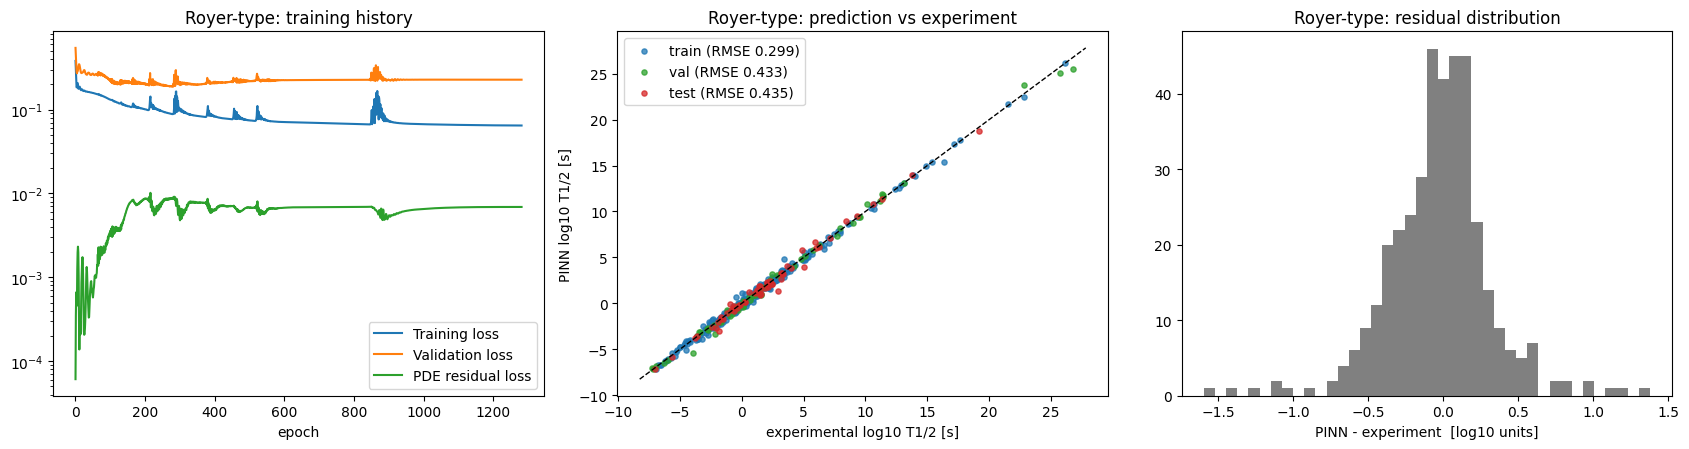

saved alpha_royer_results.png and alpha_royer_predictions.csv


,name,Z,A,Q,l,BR,logT,pred_logT,residual,split
80,184Tl,81,184,6.317375,1.0,1.22,2.891364,1.296908,-1.594456,test
243,218Pa,91,218,9.791380,3.0,100.00,-3.966576,-5.396409,-1.429833,val
255,220At,85,220,6.076844,4.0,8.00,3.444435,4.822869,1.378434,train
165,209Bi,83,209,3.137297,5.0,100.00,26.802300,25.535063,-1.267237,val
176,210Ac,89,210,7.586022,4.0,100.00,-0.455932,0.725311,1.181243,train
86,186Bi,83,186,7.756800,1.0,100.00,-1.829738,-2.971469,-1.141731,test
289,225Np,93,225,8.818245,0.0,100.00,-2.187087,-3.309220,-1.122134,val
322,237Cf,98,237,8.219999,2.0,70.00,0.057992,1.159799,1.101808,train
280,224Ac,89,224,6.326900,1.0,9.50,5.022624,3.989174,-1.033450,test
47,174Hf,72,174,2.494430,0.0,100.00,22.800134,23.789588,0.989454,val


In [10]:
if "Royer" in RESULTS:
    plot_results("Royer")          # training history | prediction vs experiment | residual histogram

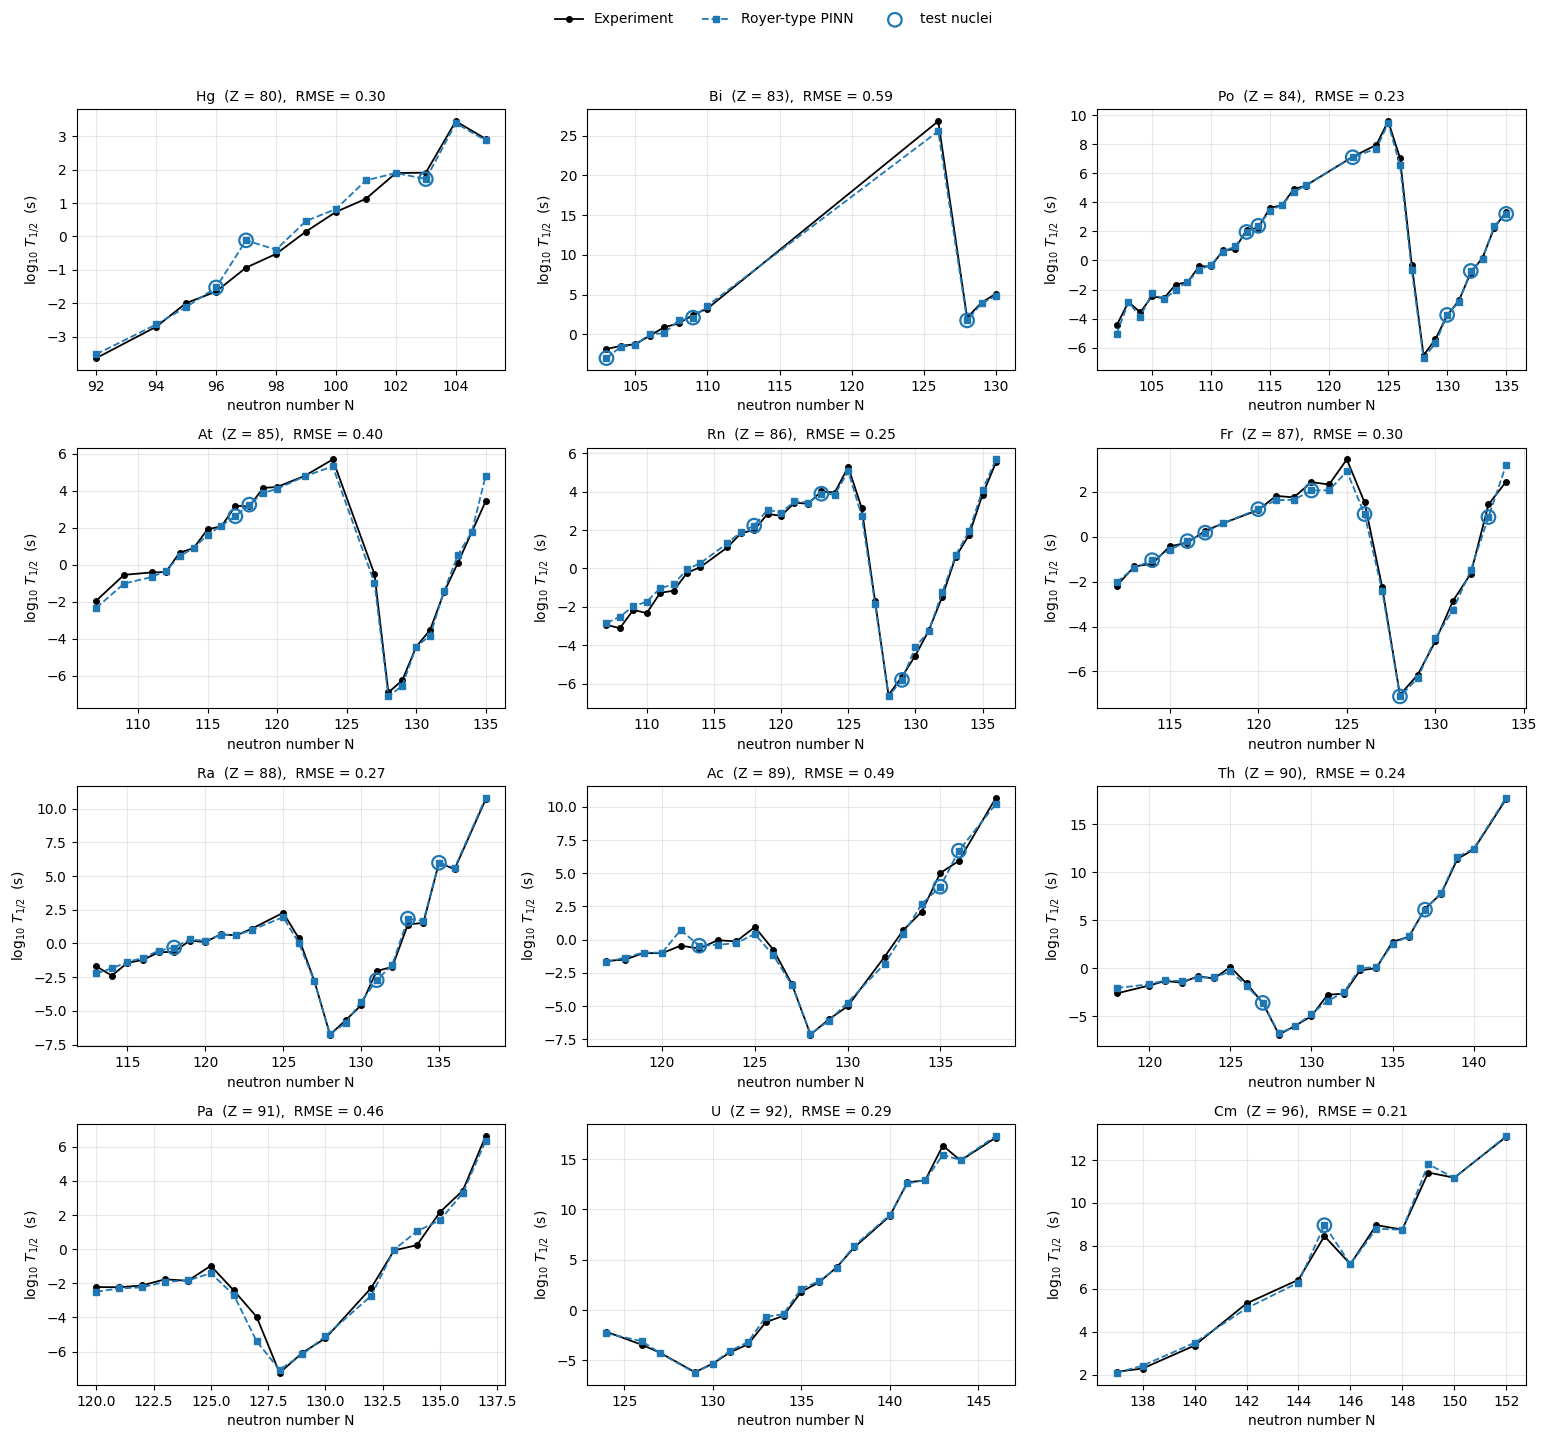

In [11]:
if "Royer" in RESULTS:
    plot_per_element("Royer")      # log10 T1/2 vs N for the isotope chain of each element

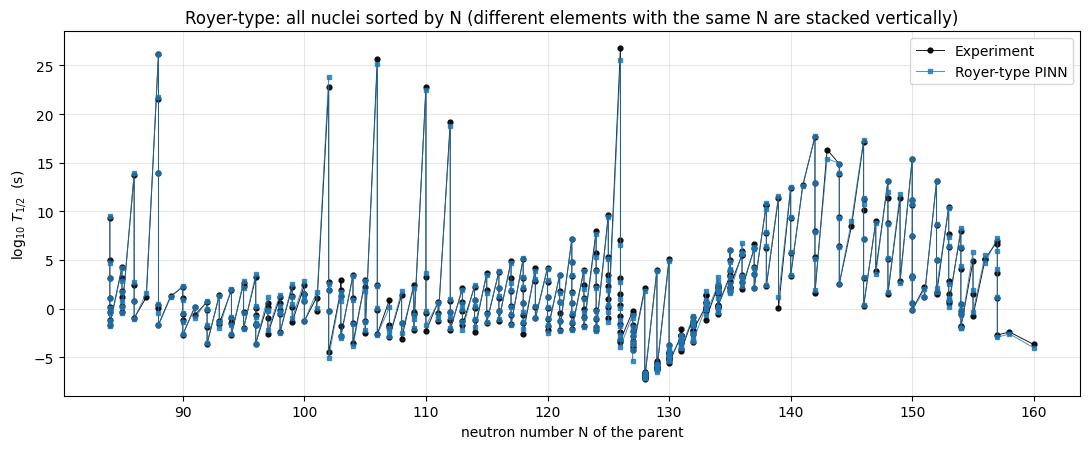

In [12]:
if "Royer" in RESULTS:
    plot_all_in_one("Royer")       # all nuclei sorted by N

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Royer-type] max |f_from_features - model prediction| = 2.842170943040401e-14


[Royer-type] SHAP additivity check (base value + sum of SHAP = prediction): max error = 8.22e-15


,mean |SHAP| (log10 s),share (%)
Qa,4.959,54.753
Zp,3.122,34.473
mu,0.540,5.963
l,0.387,4.274
Zd,0.049,0.537


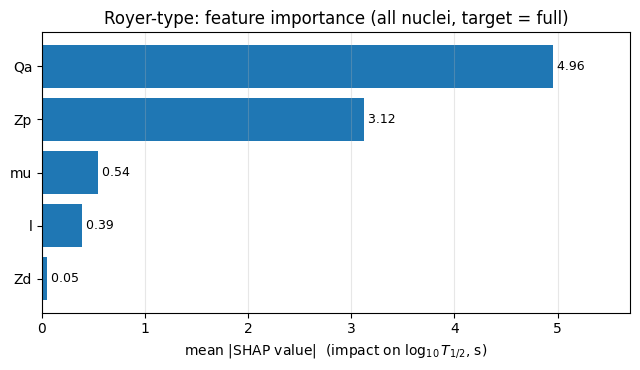

/tmp/ipykernel_110/3987741399.py:156: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_ex_df, feature_names=FEATURES, show=False)


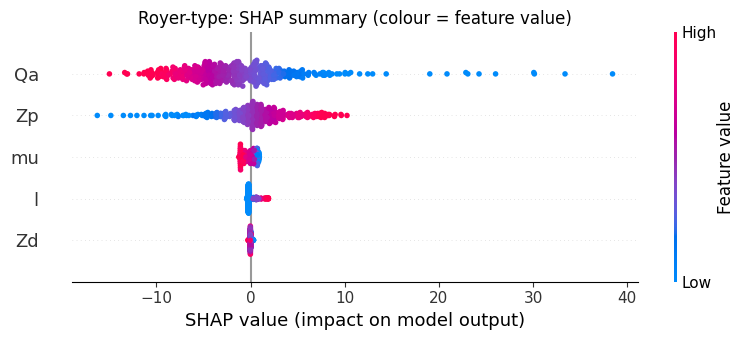

In [13]:
if "Royer" in RESULTS:
    shap_plots("Royer")            # SHAP bar chart + beeswarm

[Royer-type] 76 N values, 386 nuclei (all); RMSE between the two mean curves = 0.250


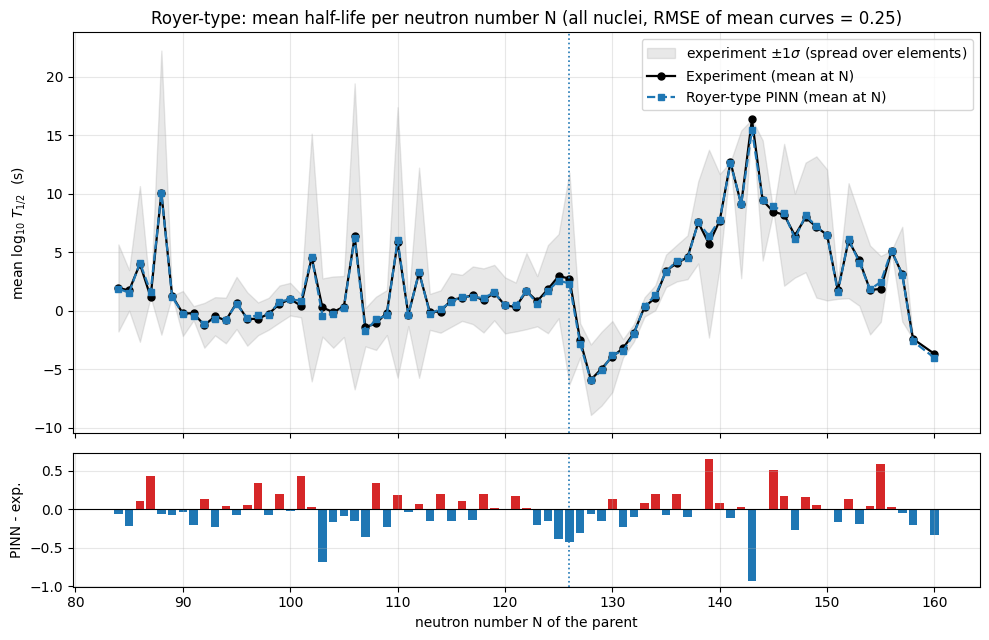

In [14]:
if "Royer" in RESULTS:
    plot_mean_vs_N("Royer")        # mean half-life per neutron number

### 5.2 Denisov PINN

In [15]:
if "Denisov" in RESULTS:
    model_summary("Denisov")

===== Denisov PINN =====  hidden layers (64, 64, 64), lambda_PDE 1.0, best epoch 2676


,N,RMSE_PINN,MAE_PINN,RMSE_closed_form
train,270.0,0.2348,0.1708,0.3546
val,58.0,0.3768,0.2606,0.4489
test,58.0,0.3059,0.2270,0.3781
all,386.0,0.2719,0.1927,0.3738


learned coefficients: a = -23.4055, b = 4.6846, c = 1.5853, d = 0.4155, e = -0.3095
PDE residual RMS (all data): Z: 0.0617, A: 0.0399, l: 0.0423


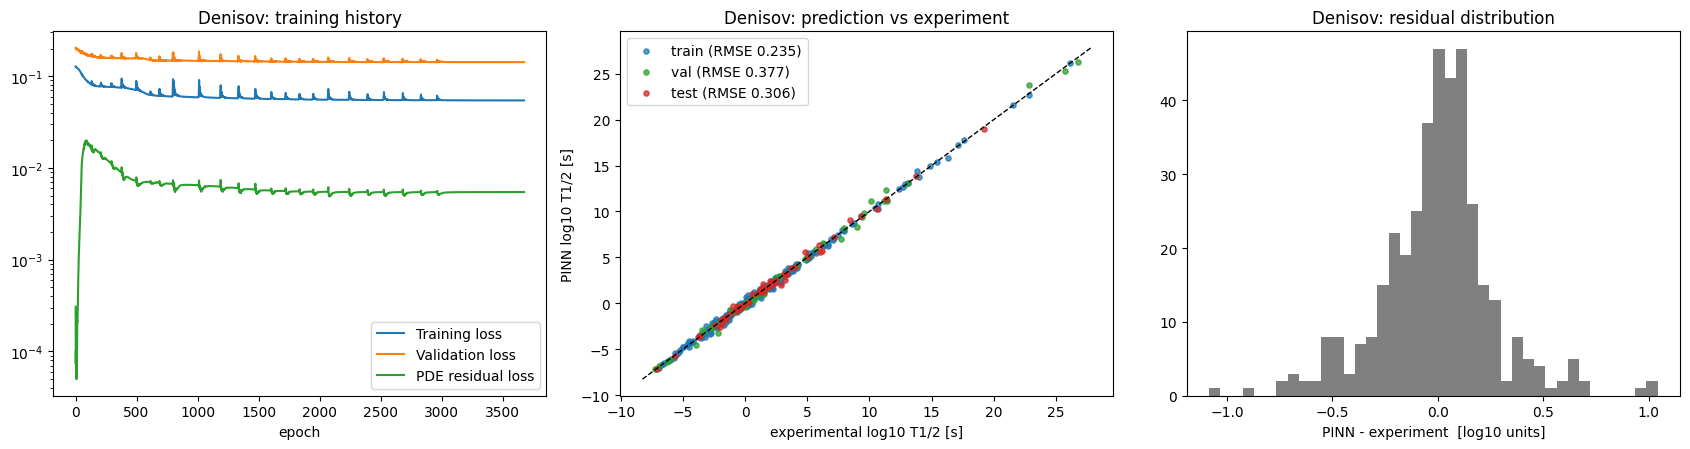

saved alpha_denisov_results.png and alpha_denisov_predictions.csv


,name,Z,A,Q,l,BR,logT,pred_logT,residual,split
289,225Np,93,225,8.818245,0.0,100.00,-2.187087,-3.271829,-1.084742,val
329,241Am,95,241,5.637820,1.0,100.00,10.135190,11.176859,1.041668,val
47,174Hf,72,174,2.494430,0.0,100.00,22.800134,23.818057,1.017923,val
334,243Am,95,243,5.439084,1.0,100.00,11.365391,12.319950,0.954559,val
80,184Tl,81,184,6.317375,1.0,1.22,2.891364,1.974726,-0.916638,test
304,229Pu,94,229,7.598007,2.0,50.00,2.260071,1.528110,-0.731961,train
287,225Pa,91,225,7.400676,2.0,100.00,0.232996,0.955416,0.722419,train
83,185Pb,82,185,6.695000,2.0,34.00,1.267862,0.545679,-0.722183,train
350,250Md,101,250,8.155422,2.0,7.00,2.887296,2.194706,-0.692590,train
364,255Fm,100,255,7.240568,4.0,100.00,4.858850,5.547315,0.688465,test


In [16]:
if "Denisov" in RESULTS:
    plot_results("Denisov")          # training history | prediction vs experiment | residual histogram

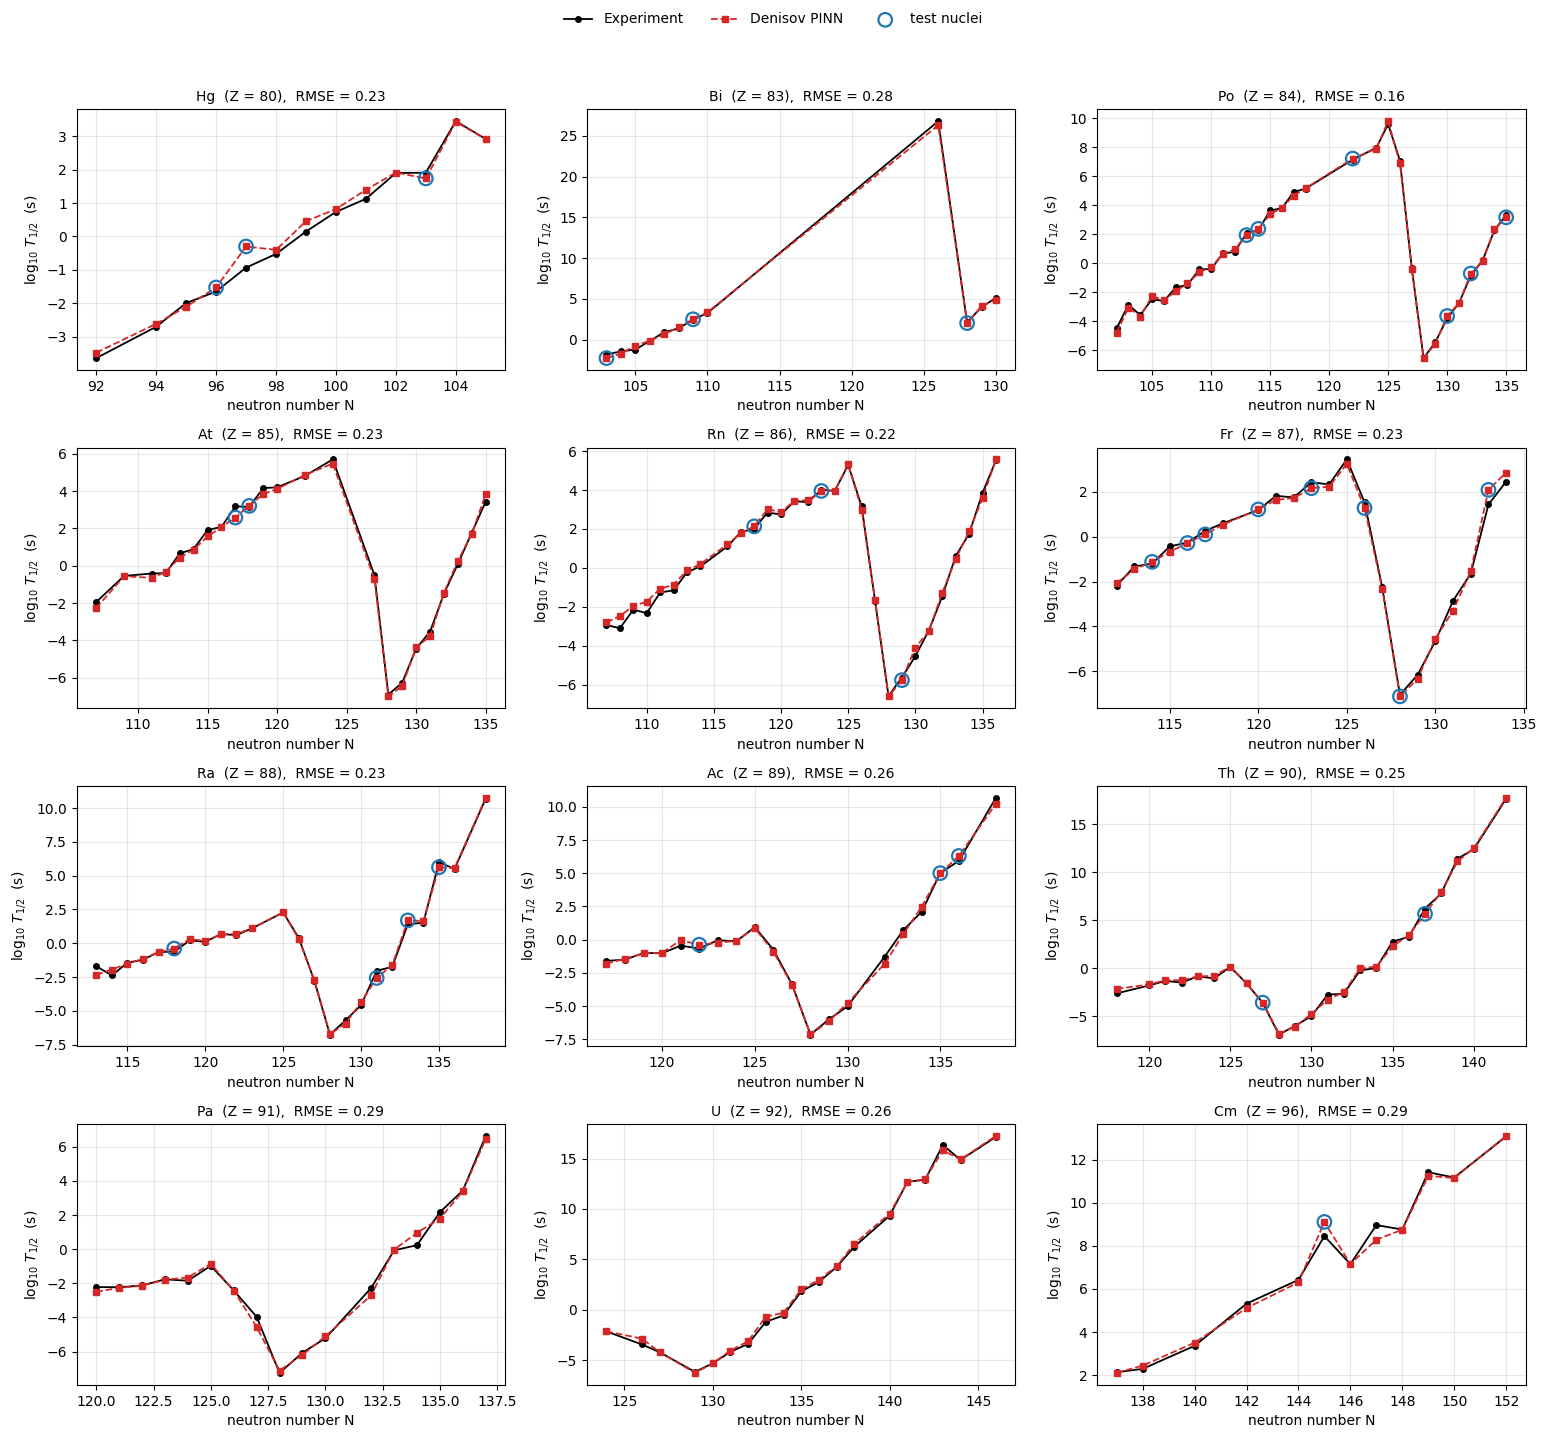

In [17]:
if "Denisov" in RESULTS:
    plot_per_element("Denisov")      # log10 T1/2 vs N for the isotope chain of each element

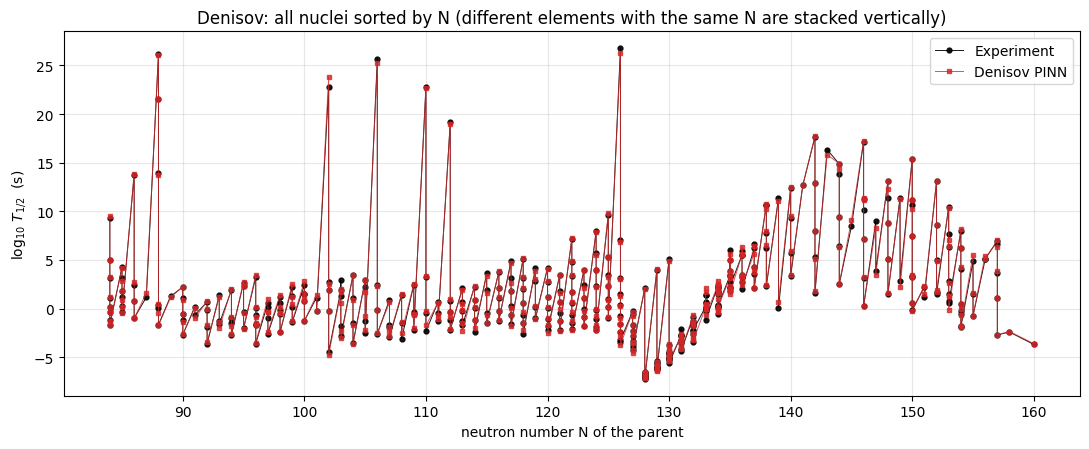

In [18]:
if "Denisov" in RESULTS:
    plot_all_in_one("Denisov")       # all nuclei sorted by N

[Denisov] max |f_from_features - model prediction| = 2.7977620220553945e-14


[Denisov] SHAP additivity check (base value + sum of SHAP = prediction): max error = 7.99e-15


,mean |SHAP| (log10 s),share (%)
Qa,4.847,55.894
Zp,2.936,33.855
mu,0.395,4.555
l,0.386,4.457
Zd,0.107,1.239


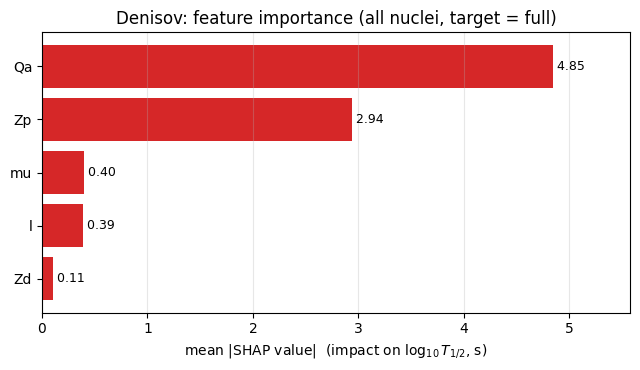

/tmp/ipykernel_110/3987741399.py:156: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_ex_df, feature_names=FEATURES, show=False)


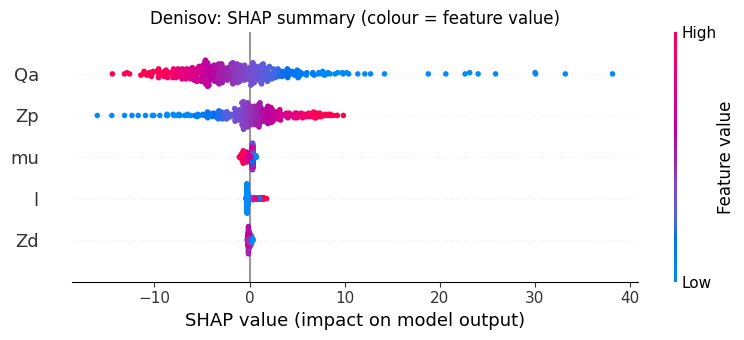

In [19]:
if "Denisov" in RESULTS:
    shap_plots("Denisov")            # SHAP bar chart + beeswarm

[Denisov] 76 N values, 386 nuclei (all); RMSE between the two mean curves = 0.195


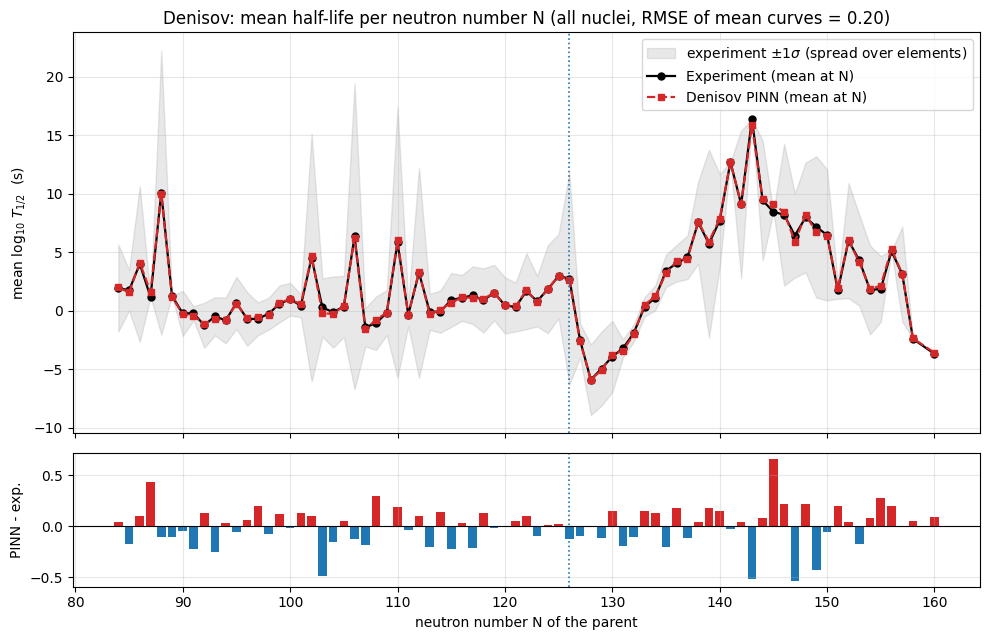

In [20]:
if "Denisov" in RESULTS:
    plot_mean_vs_N("Denisov")        # mean half-life per neutron number

### 5.3 Viola–Seaborg PINN

In [21]:
if "ViolaSeaborg" in RESULTS:
    model_summary("ViolaSeaborg")

===== Viola-Seaborg PINN =====  hidden layers (64, 64, 64), lambda_PDE 1.0, best epoch 352


,N,RMSE_PINN,MAE_PINN,RMSE_closed_form
train,270.0,0.2623,0.1940,0.6337
val,58.0,0.4338,0.2956,0.8296
test,58.0,0.3784,0.2758,0.6306
all,386.0,0.3129,0.2215,0.6664


learned coefficients: a = 1.3573, b = 16.0888, c = -0.1271, d = -38.5123
PDE residual RMS (all data): Z: 0.1111


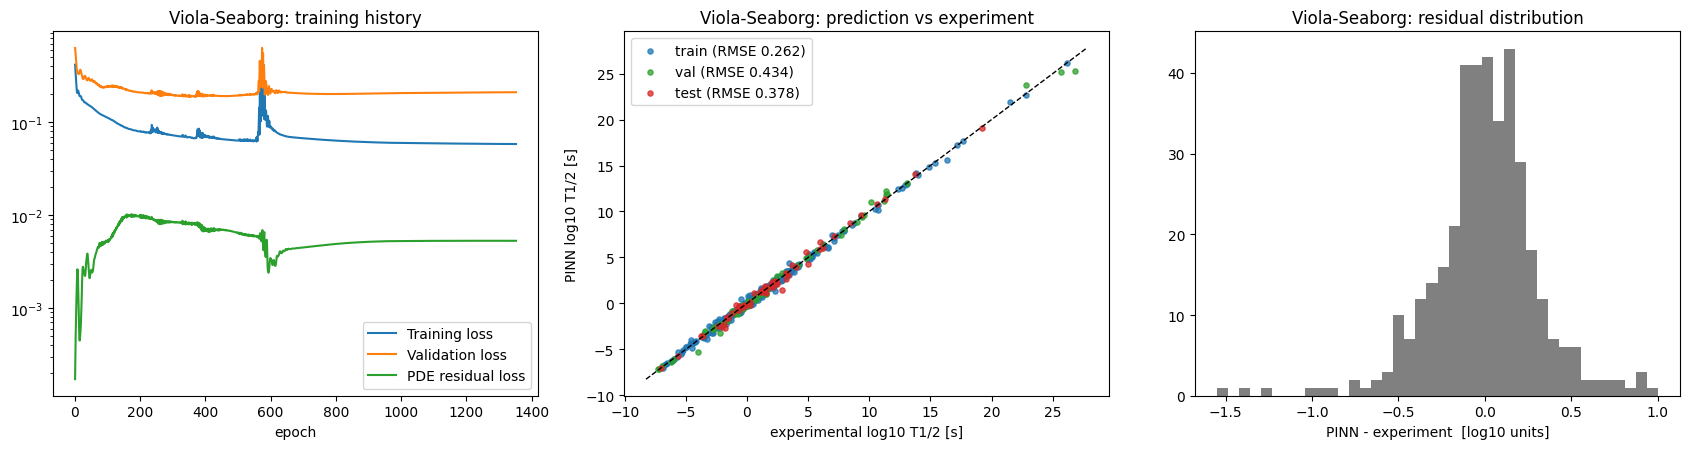

saved alpha_violaseaborg_results.png and alpha_violaseaborg_predictions.csv


,name,Z,A,Q,l,BR,logT,pred_logT,residual,split
165,209Bi,83,209,3.137297,5.0,100.00,26.802300,25.251888,-1.550412,val
80,184Tl,81,184,6.317375,1.0,1.22,2.891364,1.494856,-1.396508,test
243,218Pa,91,218,9.791380,3.0,100.00,-3.966576,-5.253139,-1.286563,val
289,225Np,93,225,8.818245,0.0,100.00,-2.187087,-3.190263,-1.003176,val
47,174Hf,72,174,2.494430,0.0,100.00,22.800134,23.802410,1.002276,val
329,241Am,95,241,5.637820,1.0,100.00,10.135190,11.066369,0.931178,val
304,229Pu,94,229,7.598007,2.0,50.00,2.260071,1.329814,-0.930258,train
255,220At,85,220,6.076844,4.0,8.00,3.444435,4.350383,0.905948,train
176,210Ac,89,210,7.586022,4.0,100.00,-0.455932,0.430840,0.886772,train
86,186Bi,83,186,7.756800,1.0,100.00,-1.829738,-2.713113,-0.883375,test


In [22]:
if "ViolaSeaborg" in RESULTS:
    plot_results("ViolaSeaborg")          # training history | prediction vs experiment | residual histogram

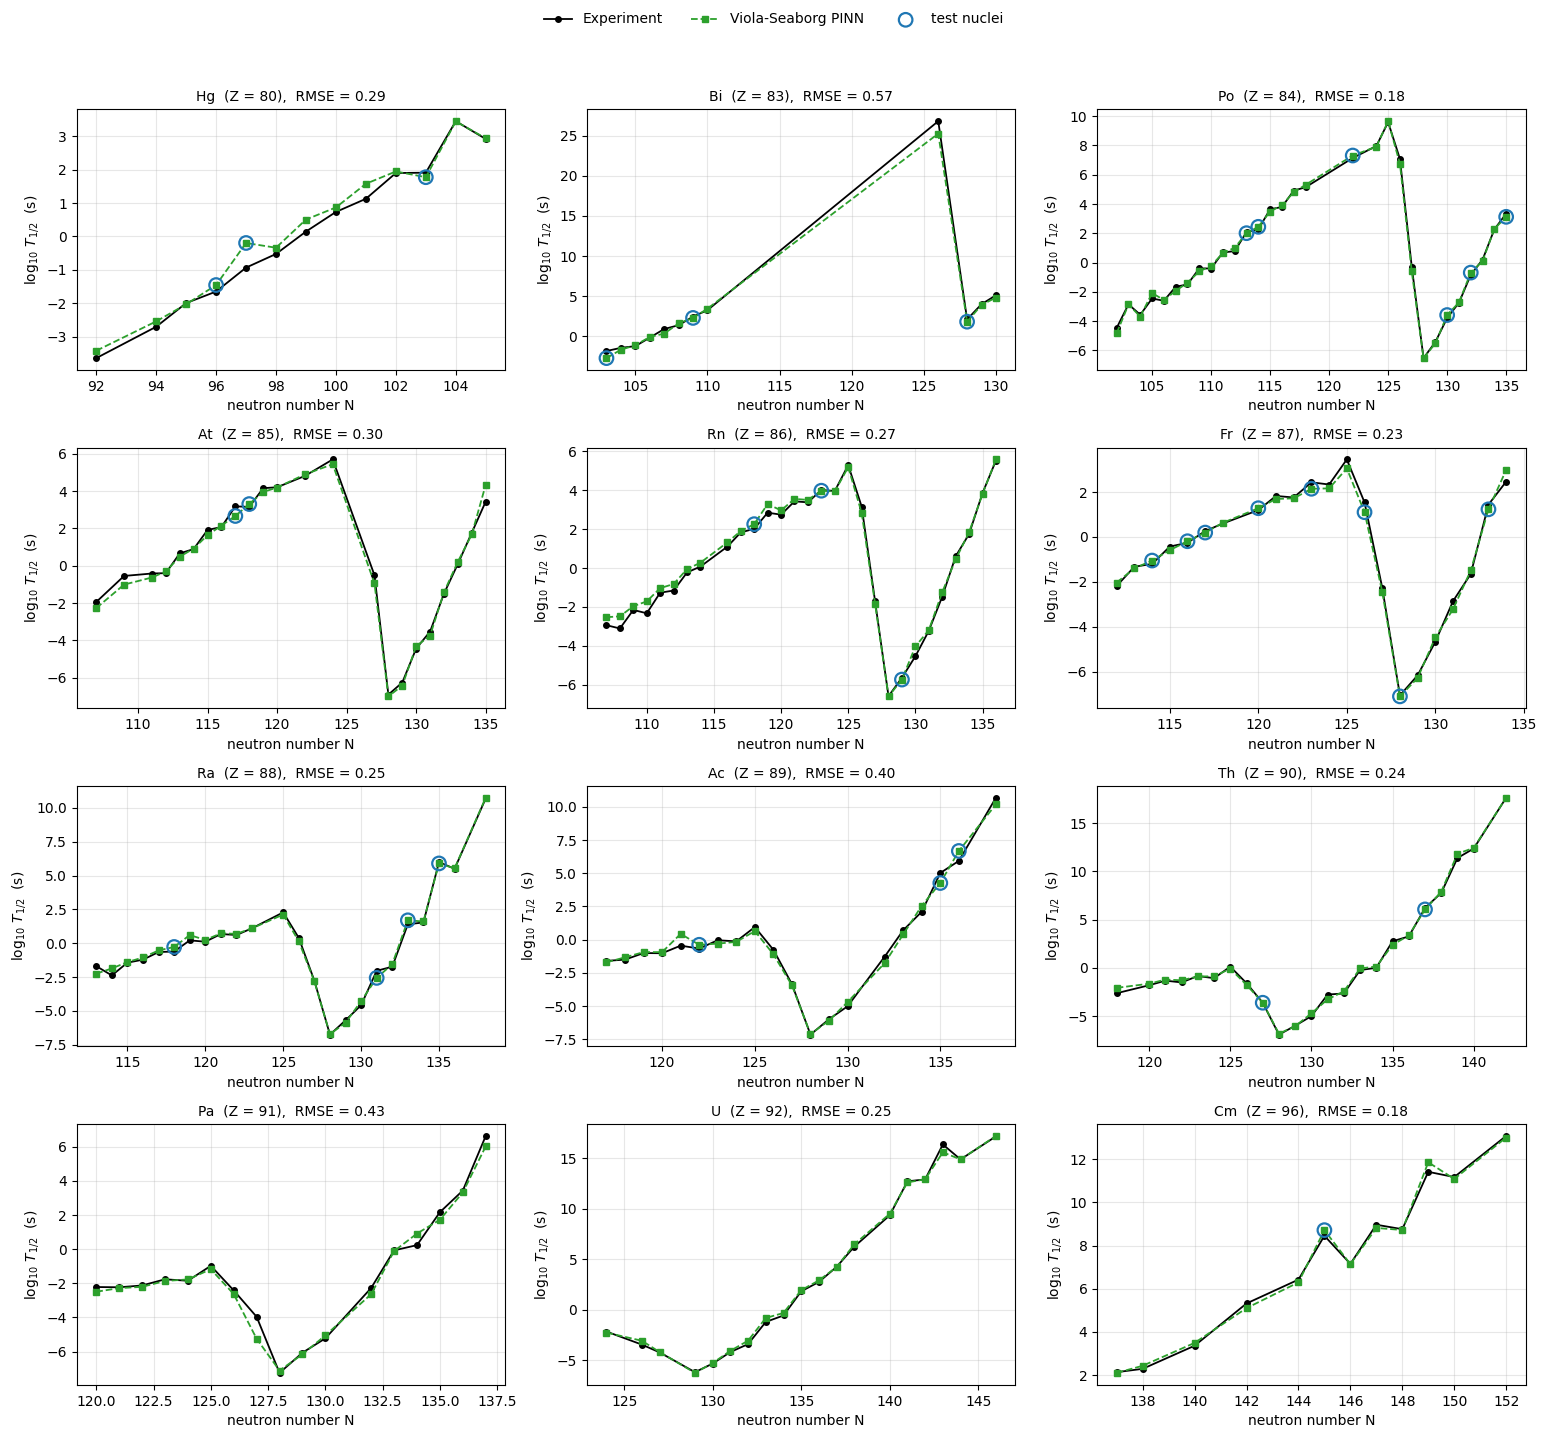

In [23]:
if "ViolaSeaborg" in RESULTS:
    plot_per_element("ViolaSeaborg")      # log10 T1/2 vs N for the isotope chain of each element

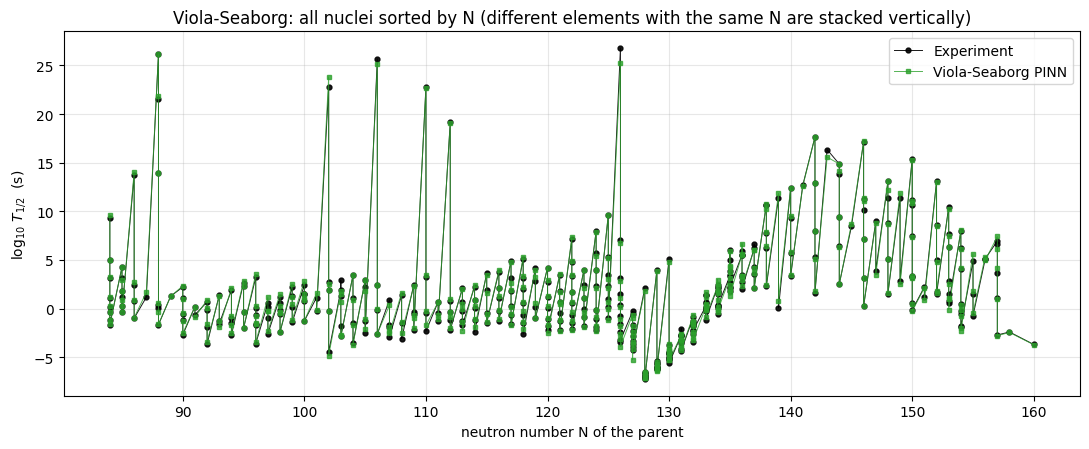

In [24]:
if "ViolaSeaborg" in RESULTS:
    plot_all_in_one("ViolaSeaborg")       # all nuclei sorted by N

[Viola-Seaborg] max |f_from_features - model prediction| = 0.0


[Viola-Seaborg] SHAP additivity check (base value + sum of SHAP = prediction): max error = 3.55e-15


,mean |SHAP| (log10 s),share (%)
Qa,4.921,57.466
Zp,2.554,29.829
mu,0.398,4.649
l,0.377,4.399
Zd,0.313,3.658


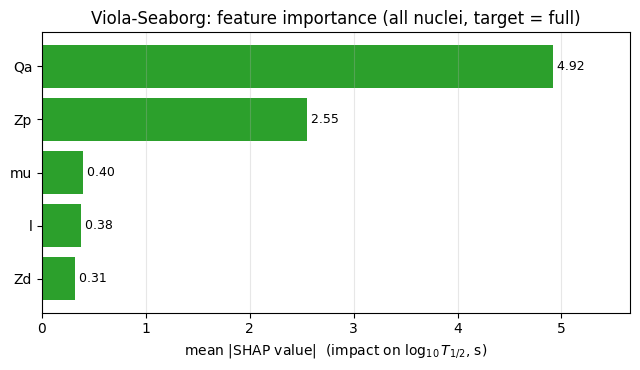

/tmp/ipykernel_110/3987741399.py:156: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_ex_df, feature_names=FEATURES, show=False)


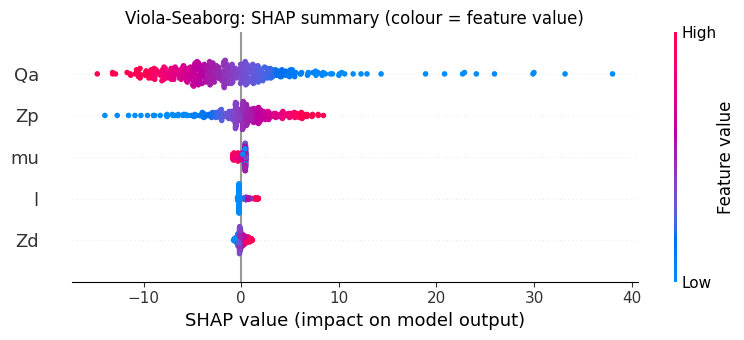

In [25]:
if "ViolaSeaborg" in RESULTS:
    shap_plots("ViolaSeaborg")            # SHAP bar chart + beeswarm

[Viola-Seaborg] 76 N values, 386 nuclei (all); RMSE between the two mean curves = 0.215


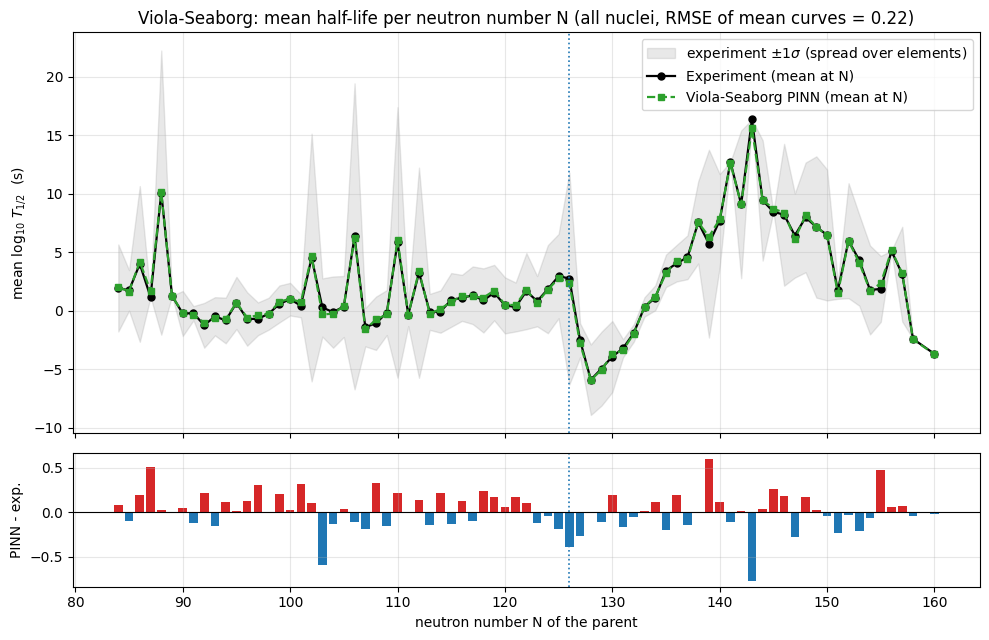

In [26]:
if "ViolaSeaborg" in RESULTS:
    plot_mean_vs_N("ViolaSeaborg")        # mean half-life per neutron number

### 5.4 Brown PINN

In [27]:
if "Brown" in RESULTS:
    model_summary("Brown")

===== Brown PINN =====  hidden layers (128, 128, 128), lambda_PDE 1.0, best epoch 441


,N,RMSE_PINN,MAE_PINN,RMSE_closed_form
train,270.0,0.2776,0.2101,0.7586
val,58.0,0.4656,0.3083,0.9722
test,58.0,0.3419,0.2497,0.8224
all,386.0,0.3226,0.2308,0.8039


learned coefficients: k = 8.9587, d = -48.6362
PDE residual RMS (all data): Z: 0.1234


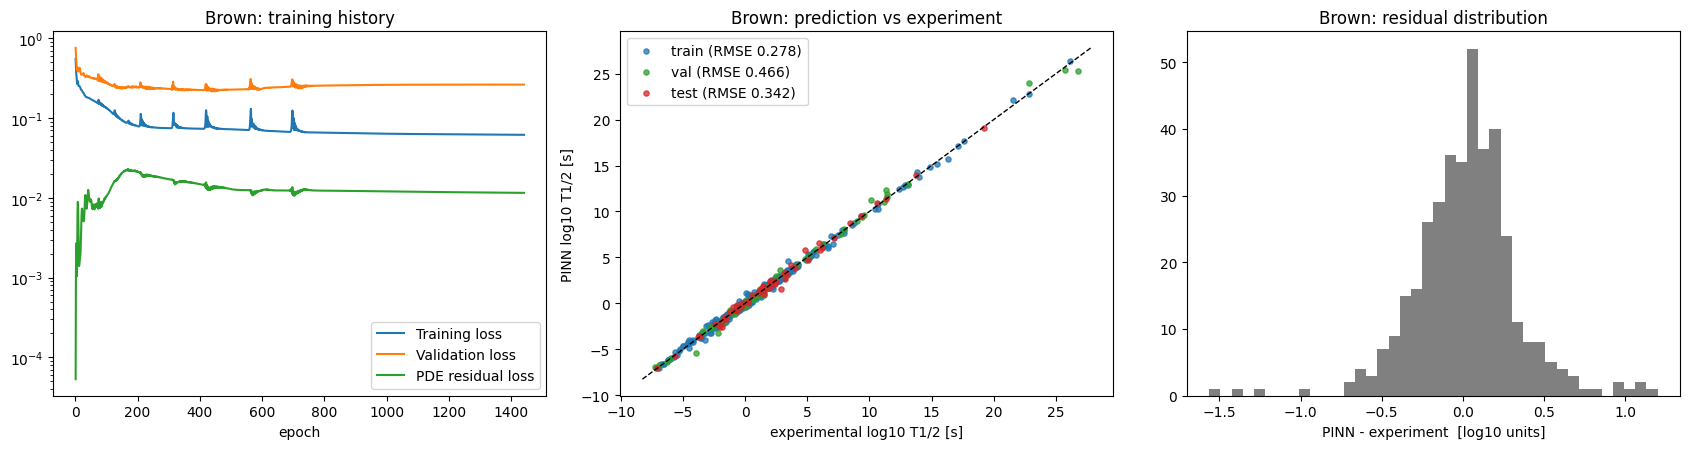

saved alpha_brown_results.png and alpha_brown_predictions.csv


,name,Z,A,Q,l,BR,logT,pred_logT,residual,split
165,209Bi,83,209,3.137297,5.0,100.00,26.802300,25.238723,-1.563577,val
243,218Pa,91,218,9.791380,3.0,100.00,-3.966576,-5.363003,-1.396427,val
80,184Tl,81,184,6.317375,1.0,1.22,2.891364,1.613066,-1.278298,test
47,174Hf,72,174,2.494430,0.0,100.00,22.800134,24.001105,1.200971,val
255,220At,85,220,6.076844,4.0,8.00,3.444435,4.575138,1.130703,train
329,241Am,95,241,5.637820,1.0,100.00,10.135190,11.242143,1.106953,val
322,237Cf,98,237,8.219999,2.0,70.00,0.057992,1.086480,1.028489,train
289,225Np,93,225,8.818245,0.0,100.00,-2.187087,-3.181501,-0.994414,val
334,243Am,95,243,5.439084,1.0,100.00,11.365391,12.338239,0.972848,val
364,255Fm,100,255,7.240568,4.0,100.00,4.858850,5.805211,0.946361,test


In [28]:
if "Brown" in RESULTS:
    plot_results("Brown")          # training history | prediction vs experiment | residual histogram

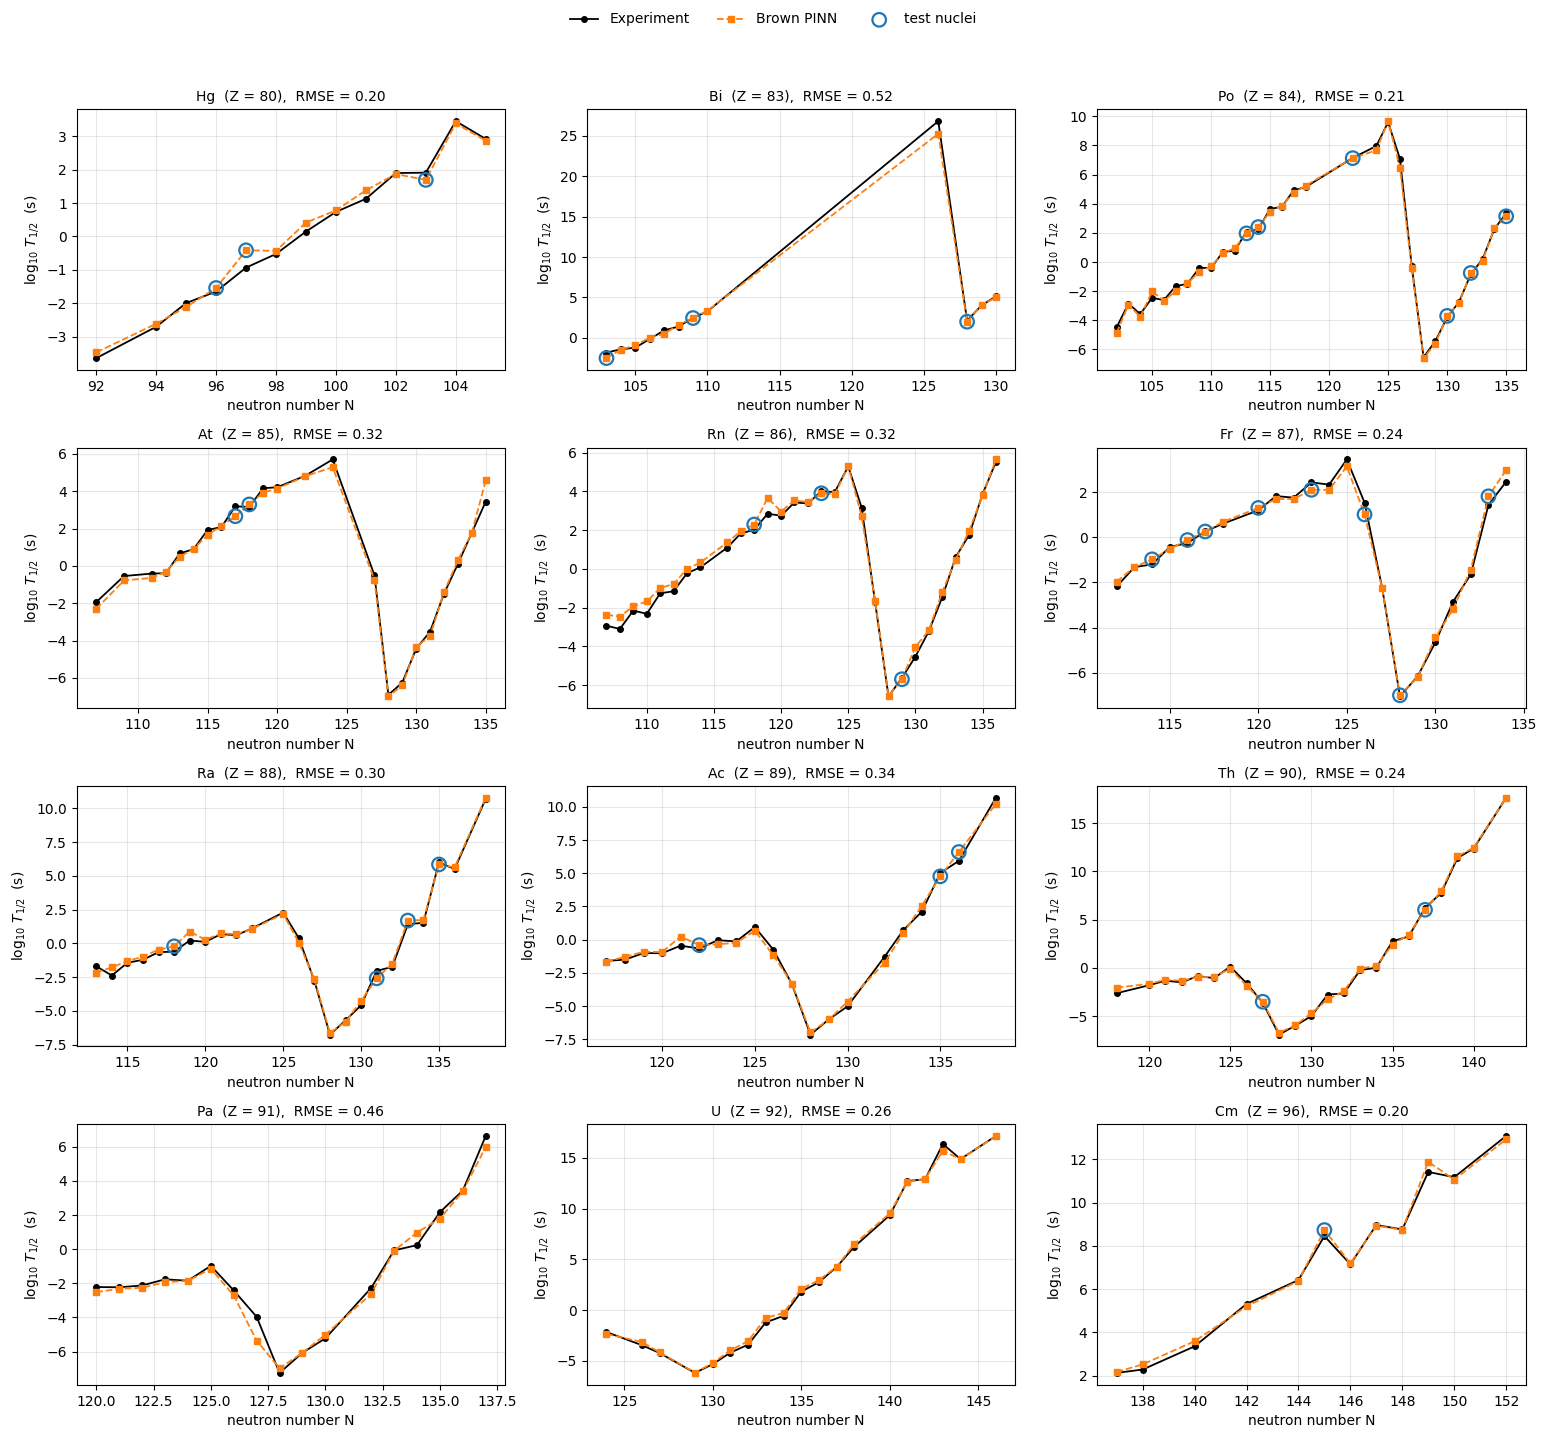

In [29]:
if "Brown" in RESULTS:
    plot_per_element("Brown")      # log10 T1/2 vs N for the isotope chain of each element

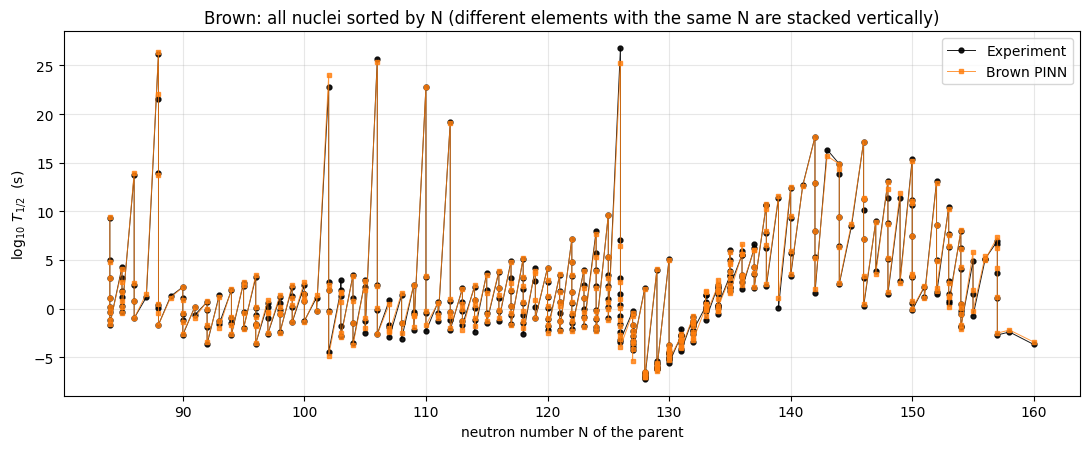

In [30]:
if "Brown" in RESULTS:
    plot_all_in_one("Brown")       # all nuclei sorted by N

[Brown] max |f_from_features - model prediction| = 0.0


[Brown] SHAP additivity check (base value + sum of SHAP = prediction): max error = 7.11e-15


,mean |SHAP| (log10 s),share (%)
Qa,4.902,55.889
Zp,2.626,29.938
mu,0.489,5.574
l,0.419,4.774
Zd,0.336,3.826


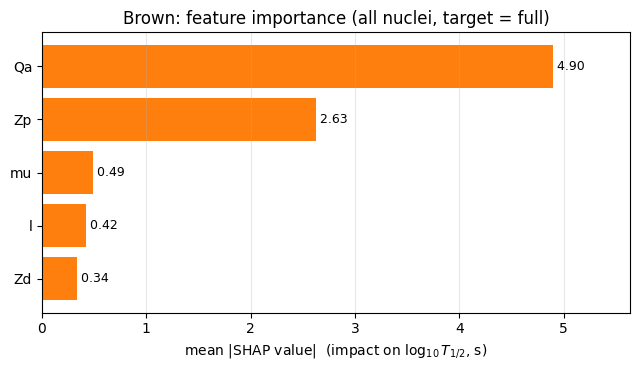

/tmp/ipykernel_110/3987741399.py:156: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_ex_df, feature_names=FEATURES, show=False)


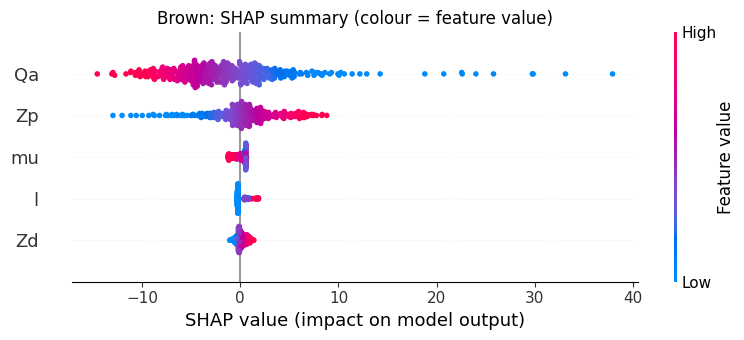

In [31]:
if "Brown" in RESULTS:
    shap_plots("Brown")            # SHAP bar chart + beeswarm

[Brown] 76 N values, 386 nuclei (all); RMSE between the two mean curves = 0.212


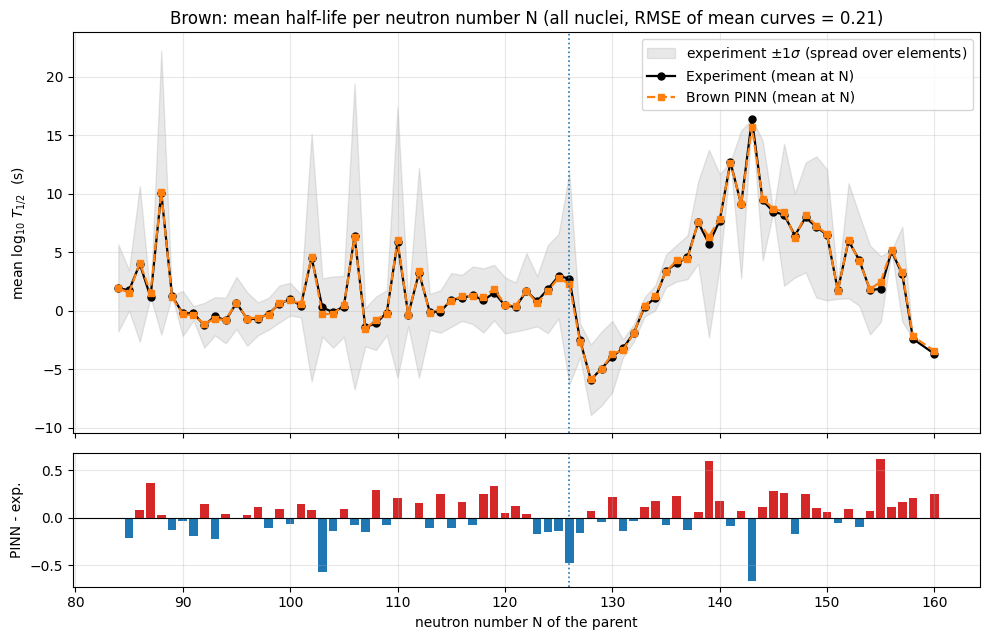

In [32]:
if "Brown" in RESULTS:
    plot_mean_vs_N("Brown")        # mean half-life per neutron number

## 6. Comparison of the four PINN models

All models are evaluated on exactly the same nuclei and the same train / validation / test split.

### 6.1 Test-RMSE table

In [33]:
rows = []
for name in MODELS:
    m = RESULTS[name]["metrics"]
    rows.append({"Model": LABEL[name], "Test N": m["test"]["N"],
                 "Test RMSE": m["test"]["RMSE_PINN"], "Test MAE": m["test"]["MAE_PINN"],
                 "Val RMSE": m["val"]["RMSE_PINN"], "Train RMSE": m["train"]["RMSE_PINN"], "All-data RMSE": m["all"]["RMSE_PINN"],
                 "Closed-form law only, test RMSE": m["test"]["RMSE_closed_form"]})
cmp_tab = pd.DataFrame(rows).set_index("Model")
cmp_tab.insert(0, "Rank (test RMSE)", cmp_tab["Test RMSE"].rank(method="min").astype(int))
cmp_tab = cmp_tab.sort_values("Test RMSE")

print("Test RMSE of the four PINN models (log10 T1/2 units; same test nuclei for every model)")
display(cmp_tab[["Rank (test RMSE)", "Test N", "Test RMSE"]].round(4))
print("\nFull comparison (train / validation / test / all data; last column = plain least-squares fit of the same law without the network)")
display(cmp_tab.round(4))
cmp_tab.to_csv(f"{PLOT['SAVE_PREFIX']}_model_comparison_rmse.csv")
best = cmp_tab.index[0]
print(f"\nLowest test RMSE: {best} ({cmp_tab.loc[best, 'Test RMSE']:.4f}). With only {int(cmp_tab['Test N'].iloc[0])} test nuclei, differences of a few hundredths "
      "are within split-to-split noise; see section 7 for a multi-seed comparison.")

Test RMSE of the four PINN models (log10 T1/2 units; same test nuclei for every model)


,Rank (test RMSE),Test N,Test RMSE
Model,,,
Denisov,1,58,0.3059
Brown,2,58,0.3419
Viola-Seaborg,3,58,0.3784
Royer-type,4,58,0.4353



Full comparison (train / validation / test / all data; last column = plain least-squares fit of the same law without the network)


,Rank (test RMSE),Test N,Test RMSE,Test MAE,Val RMSE,Train RMSE,All-data RMSE,"Closed-form law only, test RMSE"
Model,,,,,,,,
Denisov,1,58,0.3059,0.2270,0.3768,0.2348,0.2719,0.3781
Brown,2,58,0.3419,0.2497,0.4656,0.2776,0.3226,0.8224
Viola-Seaborg,3,58,0.3784,0.2758,0.4338,0.2623,0.3129,0.6306
Royer-type,4,58,0.4353,0.2970,0.4333,0.2985,0.3450,0.6213



Lowest test RMSE: Denisov (0.3059). With only 58 test nuclei, differences of a few hundredths are within split-to-split noise; see section 7 for a multi-seed comparison.


### 6.2 RMSE bar charts

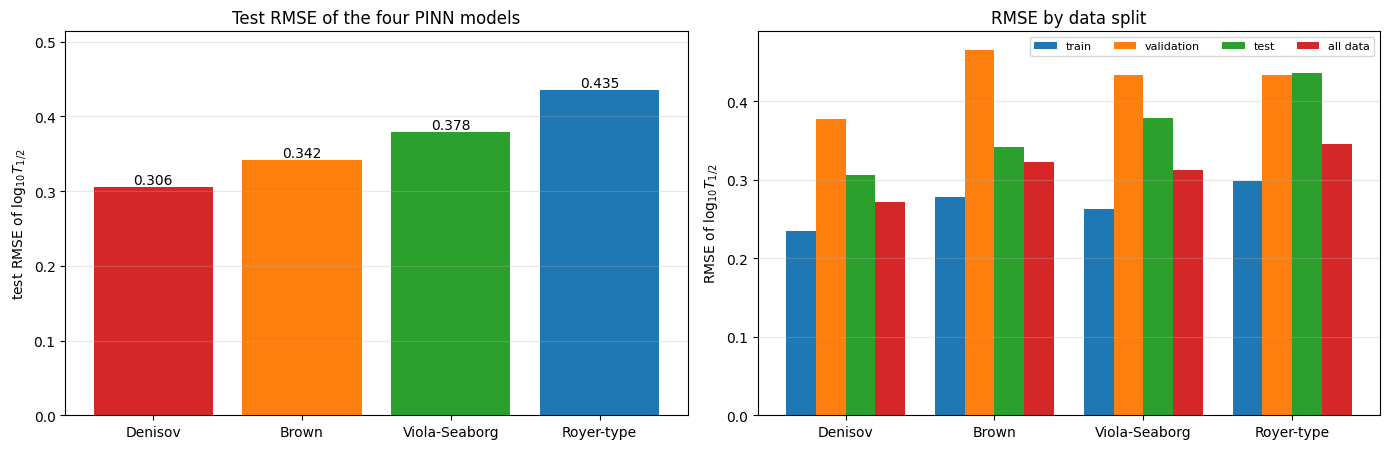

In [34]:
order = list(cmp_tab.index)                      # models sorted by test RMSE
inv = {v: k for k, v in LABEL.items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
vals = cmp_tab["Test RMSE"].values
bars = ax[0].bar(order, vals, color=[COLOR[inv[o]] for o in order])
for b_, v in zip(bars, vals):
    ax[0].text(b_.get_x() + b_.get_width() / 2, v + 0.004, f"{v:.3f}", ha="center", fontsize=10)
ax[0].set_ylabel("test RMSE of log$_{10}T_{1/2}$"); ax[0].set_title("Test RMSE of the four PINN models"); ax[0].grid(axis="y", alpha=0.3)
ax[0].set_ylim(0, vals.max() * 1.18)
w = 0.2; x = np.arange(len(order))
for i, (col, lab) in enumerate((("Train RMSE", "train"), ("Val RMSE", "validation"), ("Test RMSE", "test"), ("All-data RMSE", "all data"))):
    ax[1].bar(x + (i - 1.5) * w, cmp_tab[col].values, w, label=lab)
ax[1].set_xticks(x); ax[1].set_xticklabels(order); ax[1].set_ylabel("RMSE of log$_{10}T_{1/2}$")
ax[1].set_title("RMSE by data split"); ax[1].legend(ncol=4, fontsize=8); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{PLOT['SAVE_PREFIX']}_compare_rmse_bars.png", dpi=PLOT["DPI"]); plt.show()

### 6.3 Prediction vs experiment (all models)

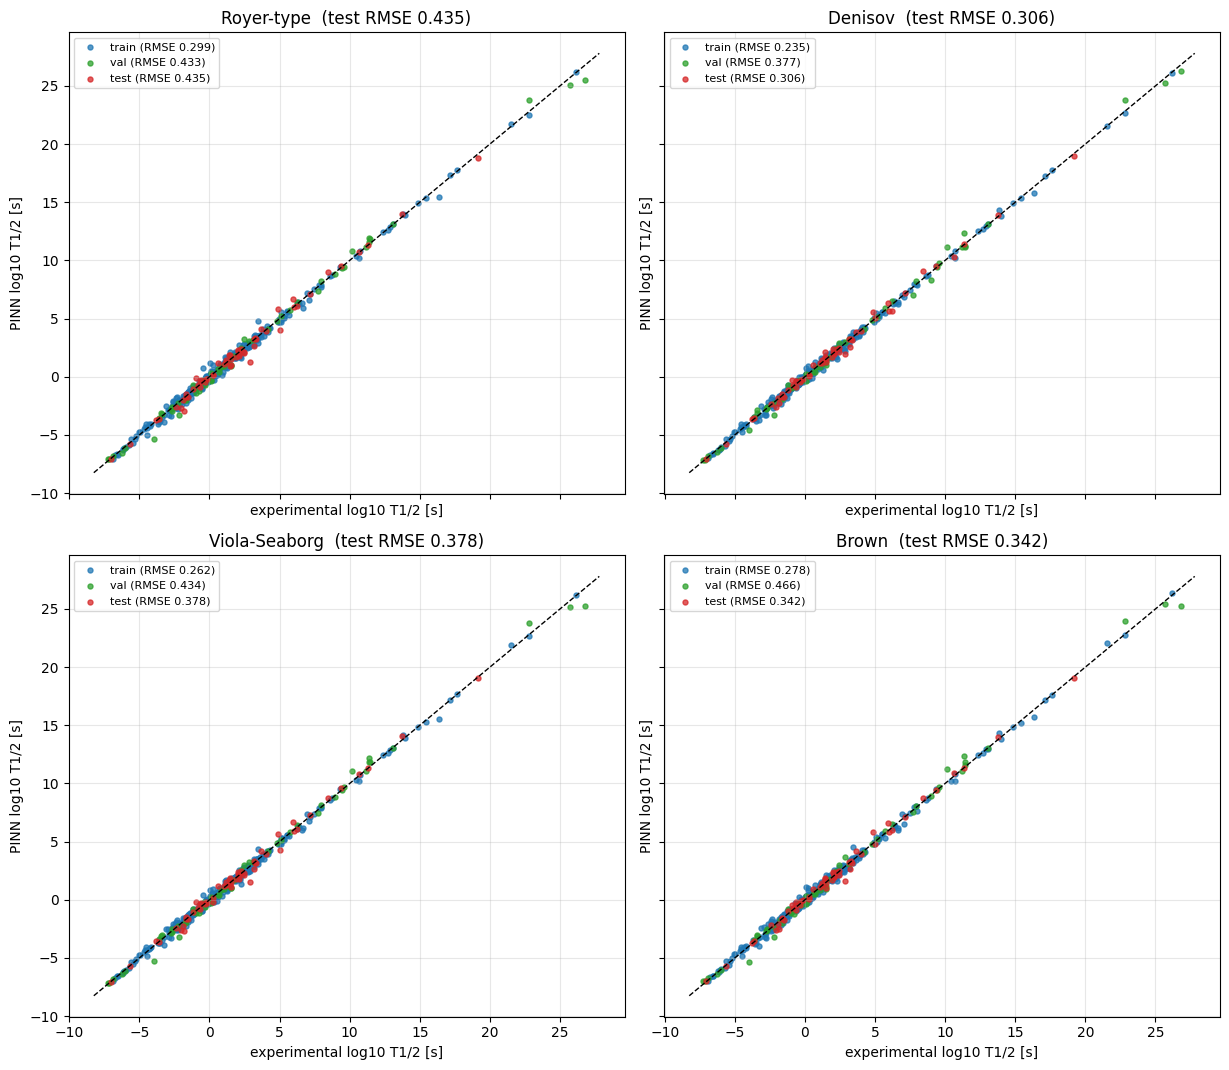

In [35]:
y = df.logT.values
ncol = 2; nrow = math.ceil(len(MODELS) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6.2 * ncol, 5.4 * nrow), squeeze=False, sharex=True, sharey=True)
lim = [y.min() - 1, y.max() + 1]
for ax, name in zip(axes.ravel(), MODELS):
    p = RESULTS[name]["pred"]
    for idx, lab, col in ((tr_idx, "train", "tab:blue"), (va_idx, "val", "tab:green"), (te_idx, "test", "tab:red")):
        ax.scatter(y[idx], p[idx], s=13, alpha=0.75, c=col, label=f"{lab} (RMSE {rmse_mae(p[idx], y[idx])[0]:.3f})")
    ax.plot(lim, lim, "k--", lw=1); ax.set_title(f"{LABEL[name]}  (test RMSE {RESULTS[name]['metrics']['test']['RMSE_PINN']:.3f})")
    ax.set_xlabel("experimental log10 T1/2 [s]"); ax.set_ylabel("PINN log10 T1/2 [s]"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
for ax in axes.ravel()[len(MODELS):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{PLOT['SAVE_PREFIX']}_compare_pred_vs_exp.png", dpi=PLOT["DPI"]); plt.show()

### 6.4 Residual distributions

/tmp/ipykernel_110/1392239208.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax[1].boxplot([RESULTS[n]["pred"] - y for n in MODELS], labels=[LABEL[n] for n in MODELS], patch_artist=True, showfliers=True, flierprops=dict(markersize=3))


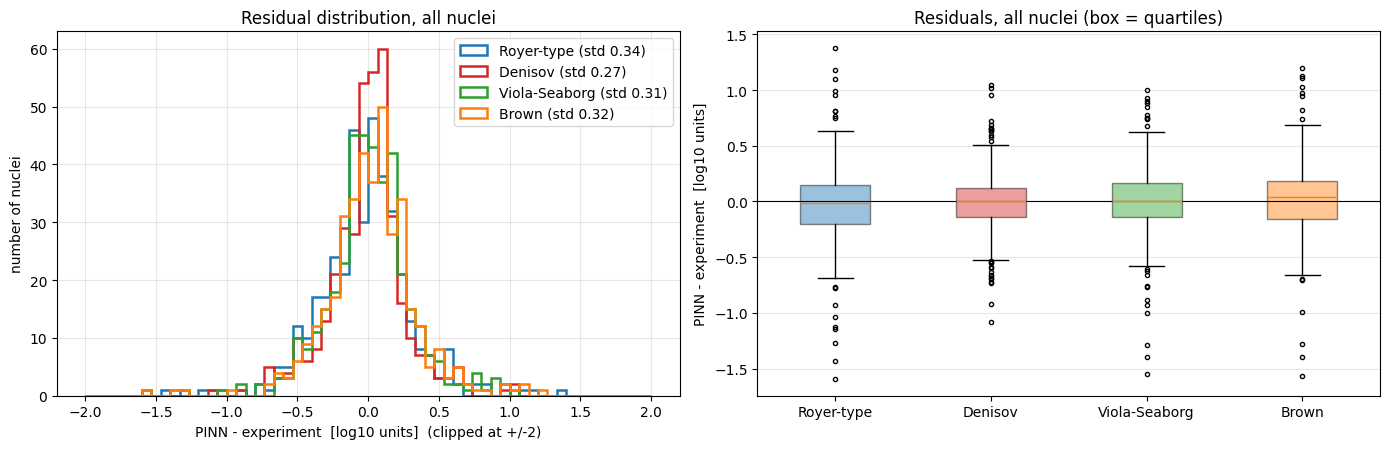

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
bins = np.linspace(-2, 2, 61)
for name in MODELS:
    r = RESULTS[name]["pred"] - y
    ax[0].hist(np.clip(r, -2, 2), bins=bins, histtype="step", lw=1.8, color=COLOR[name], label=f"{LABEL[name]} (std {r.std():.2f})")
ax[0].set_xlabel("PINN - experiment  [log10 units]  (clipped at +/-2)"); ax[0].set_ylabel("number of nuclei")
ax[0].set_title("Residual distribution, all nuclei"); ax[0].legend(); ax[0].grid(alpha=0.3)
bp = ax[1].boxplot([RESULTS[n]["pred"] - y for n in MODELS], labels=[LABEL[n] for n in MODELS], patch_artist=True, showfliers=True, flierprops=dict(markersize=3))
for patch, n in zip(bp["boxes"], MODELS):
    patch.set_facecolor(COLOR[n]); patch.set_alpha(0.45)
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_ylabel("PINN - experiment  [log10 units]"); ax[1].set_title("Residuals, all nuclei (box = quartiles)"); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{PLOT['SAVE_PREFIX']}_compare_residuals.png", dpi=PLOT["DPI"]); plt.show()

### 6.5 Half-life vs neutron number N — all models together with the experiment

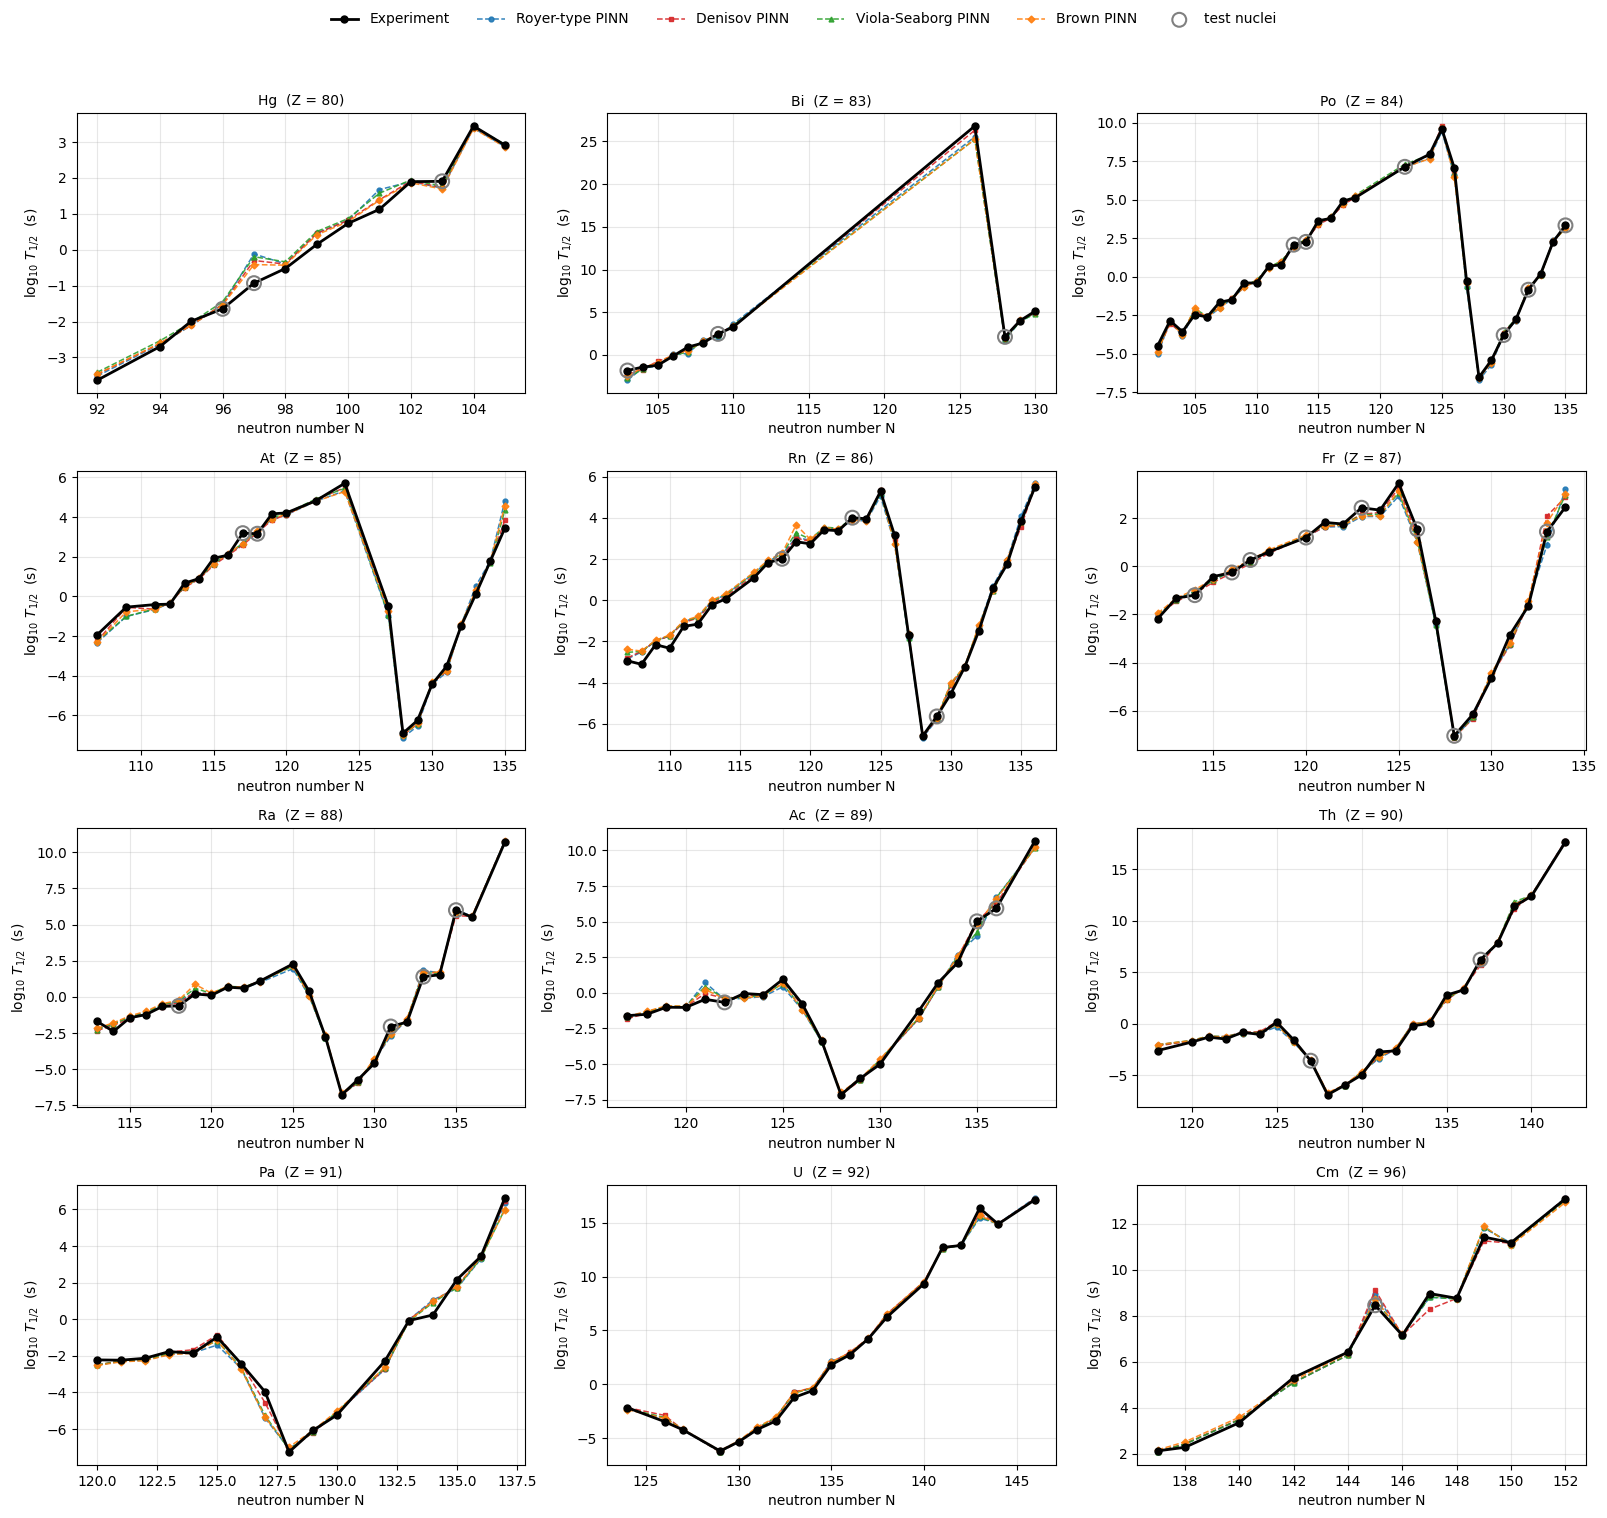

In [37]:
# (a) one panel per element: experiment (black) and the four PINN predictions along the isotope chain
base = df.copy(); base["N"] = (base["A"] - base["Z"]).astype(int)
base["symbol"] = base["name"].str.extract(r"([A-Za-z]+)")[0]
for name in MODELS:
    base[f"pred_{name}"] = RESULTS[name]["pred"]
base["split"] = "train"; base.loc[va_idx, "split"] = "val"; base.loc[te_idx, "split"] = "test"

counts = base.groupby("Z").size()
zs = counts[counts >= PLOT["MIN_ISOTOPES"]].sort_values(ascending=False).head(PLOT["MAX_PANELS"]).index.sort_values()
ncols = min(PLOT["N_COLS"], len(zs)); nrows = math.ceil(len(zs) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 3.8 * nrows), squeeze=False)
for ax, z in zip(axes.ravel(), zs):
    g = base[base.Z == z].sort_values("N")
    ax.plot(g.N, g.logT, "o-", color="black", ms=5, lw=2.0, label="Experiment", zorder=6)
    for name in MODELS:
        ax.plot(g.N, g[f"pred_{name}"], MARK[name] + "--", color=COLOR[name], ms=3.5, lw=1.1, alpha=0.9, label=f"{LABEL[name]} PINN")
    t = g[g.split == "test"]
    ax.scatter(t.N, t.logT, s=100, facecolors="none", edgecolors="gray", linewidths=1.5, zorder=7, label="test nuclei")
    ax.set_title(f"{g.symbol.iloc[0]}  (Z = {z})", fontsize=10)
    ax.set_xlabel("neutron number N"); ax.set_ylabel(r"$\log_{10}\,T_{1/2}$  (s)"); ax.grid(alpha=0.3)
for ax in axes.ravel()[len(zs):]:
    ax.axis("off")
hd = {}
for ax in axes.ravel():
    for h, l_ in zip(*ax.get_legend_handles_labels()):
        hd.setdefault(l_, h)
fig.legend(list(hd.values()), list(hd.keys()), loc="upper center", ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(f"{PLOT['SAVE_PREFIX']}_compare_halflife_vs_N_per_element.png", dpi=PLOT["DPI"]); plt.show()

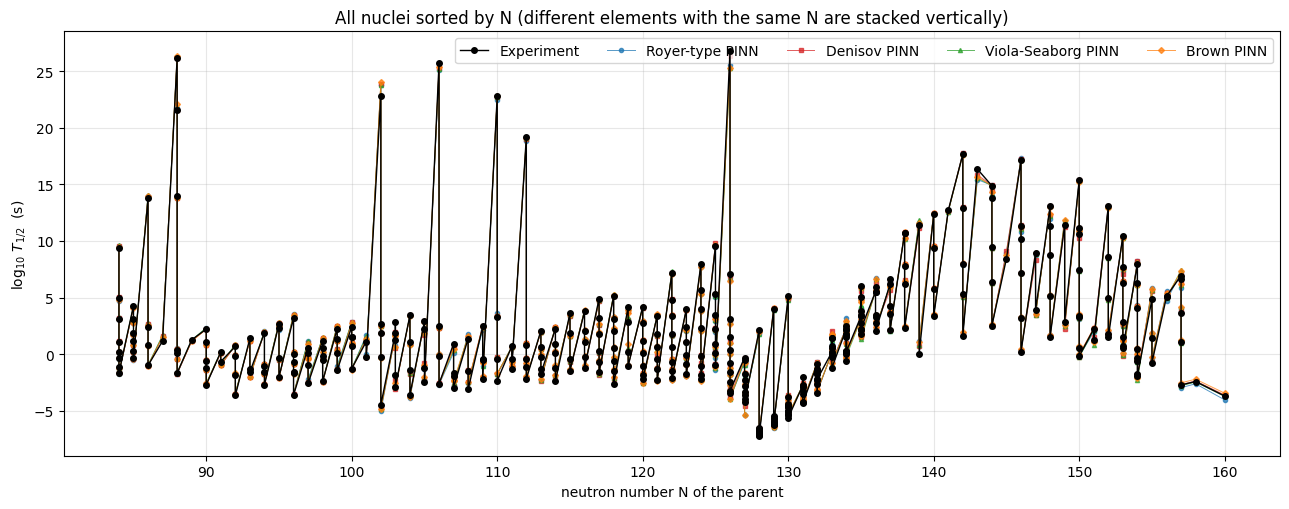

In [38]:
# (b) all nuclei sorted by N (then Z): experiment and the four PINN predictions in one graph
g = base.sort_values(["N", "Z"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.plot(g.N, g.logT, "o-", color="black", ms=4, lw=1.0, label="Experiment", zorder=6)
for name in MODELS:
    ax.plot(g.N, g[f"pred_{name}"], MARK[name] + "-", color=COLOR[name], ms=3, lw=0.7, alpha=0.75, label=f"{LABEL[name]} PINN")
ax.set_xlabel("neutron number N of the parent"); ax.set_ylabel(r"$\log_{10}\,T_{1/2}$  (s)")
ax.set_title("All nuclei sorted by N (different elements with the same N are stacked vertically)")
ax.grid(alpha=0.3); ax.legend(ncol=5)
fig.tight_layout(); fig.savefig(f"{PLOT['SAVE_PREFIX']}_compare_halflife_vs_N_all.png", dpi=PLOT["DPI"]); plt.show()

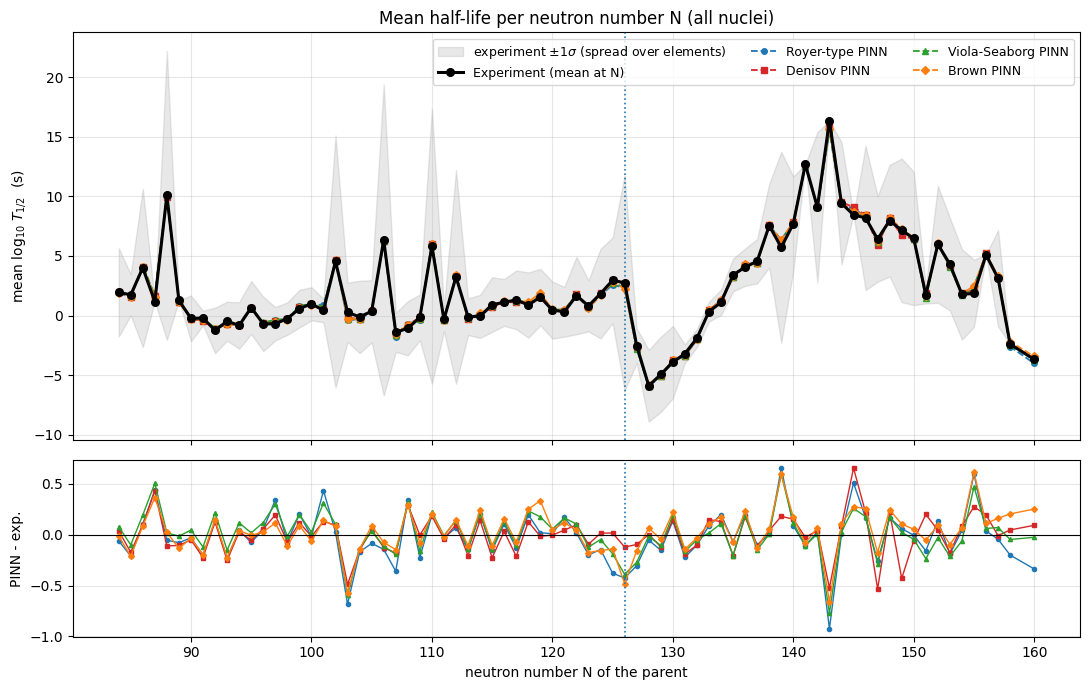

RMSE between the mean curves (model vs experiment) over the N values shown:


,RMSE between mean curves
Royer-type,0.2501
Denisov,0.1952
Viola-Seaborg,0.2153
Brown,0.2115


In [39]:
# (c) mean half-life per neutron number N: experiment and the four PINN predictions (+ deviation panel)
byN = mean_by_N({n: RESULTS[n]["pred"] for n in MODELS})
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
if MEANC["SHOW_SPREAD"]:
    sd = byN["exp_std"].fillna(0.0)
    ax.fill_between(byN["N"], byN["exp_mean"] - sd, byN["exp_mean"] + sd, color="gray", alpha=0.18, label=r"experiment $\pm1\sigma$ (spread over elements)")
ax.plot(byN["N"], byN["exp_mean"], "o-", color="black", ms=5.5, lw=2.2, label="Experiment (mean at N)", zorder=6)
for name in MODELS:
    ax.plot(byN["N"], byN[f"{name}_mean"], MARK[name] + "--", color=COLOR[name], ms=4, lw=1.3, label=f"{LABEL[name]} PINN")
    ax2.plot(byN["N"], byN[f"{name}_mean"] - byN["exp_mean"], MARK[name] + "-", color=COLOR[name], ms=3, lw=1.0, label=LABEL[name])
for n_magic in MEANC["SHELL_LINES"]:
    ax.axvline(n_magic, color="tab:blue", ls=":", lw=1.2); ax2.axvline(n_magic, color="tab:blue", ls=":", lw=1.2)
ax.set_ylabel(r"mean $\log_{10}\,T_{1/2}$  (s)"); ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=9)
ax.set_title(f"Mean half-life per neutron number N ({MEANC['SUBSET']} nuclei)")
ax2.axhline(0, color="black", lw=0.8); ax2.set_xlabel("neutron number N of the parent"); ax2.set_ylabel("PINN - exp."); ax2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(f"{PLOT['SAVE_PREFIX']}_compare_mean_halflife_vs_N.png", dpi=PLOT["DPI"]); plt.show()

mc = pd.DataFrame({"RMSE between mean curves": {LABEL[n]: float(np.sqrt(np.mean((byN[f"{n}_mean"] - byN["exp_mean"]) ** 2))) for n in MODELS}})
print("RMSE between the mean curves (model vs experiment) over the N values shown:")
display(mc.round(4))
byN.to_csv(f"{PLOT['SAVE_PREFIX']}_compare_mean_halflife_vs_N.csv", index=False)

### 6.6 Where do the errors come from? (ℓ = 0 vs ℓ > 0 and SHAP importance)

,"RMSE l = 0 (test, n=37)","RMSE l = 0 (all, n=283)","RMSE l > 0 (test, n=21)","RMSE l > 0 (all, n=103)"
Royer-type,0.2103,0.2430,0.6674,0.5327
Denisov,0.1861,0.2195,0.4443,0.3805
Viola-Seaborg,0.2056,0.2258,0.5665,0.4763
Brown,0.2106,0.2456,0.4947,0.4735


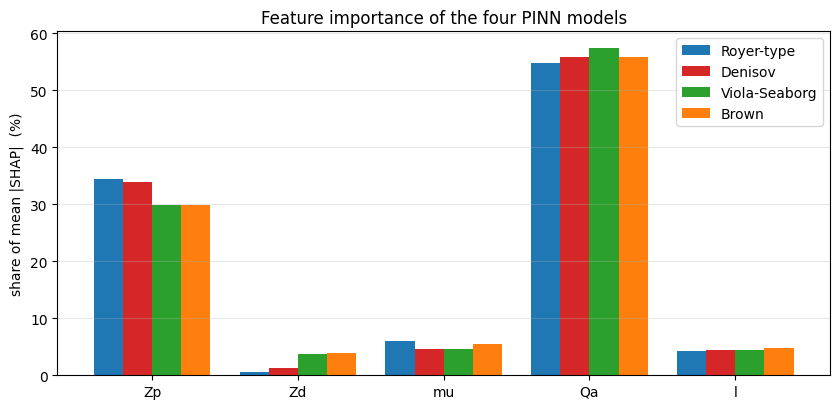

,Royer-type,Denisov,Viola-Seaborg,Brown
Zp,34.5,33.9,29.8,29.9
Zd,0.5,1.2,3.7,3.8
mu,6.0,4.6,4.6,5.6
Qa,54.8,55.9,57.5,55.9
l,4.3,4.5,4.4,4.8


In [40]:
l_arr = df.l.values
rows = {}
for name in MODELS:
    r = RESULTS[name]["pred"] - y
    row = {}
    for lab, msk in (("l = 0", l_arr == 0), ("l > 0", l_arr > 0)):
        for part, idx in (("test", te_idx), ("all", np.arange(len(df)))):
            sel = np.intersect1d(np.where(msk)[0], idx)
            row[f"RMSE {lab} ({part}, n={len(sel)})"] = float(np.sqrt(np.mean(r[sel] ** 2))) if len(sel) else float("nan")
    rows[LABEL[name]] = row
display(pd.DataFrame(rows).T.round(4))

if SHAP_TABLES:
    share = pd.DataFrame({LABEL[n]: SHAP_TABLES[n]["share (%)"] for n in MODELS if n in SHAP_TABLES}).reindex(FEATURES)
    ax = share.plot.bar(figsize=(8.5, 4.2), color=[COLOR[n] for n in MODELS if n in SHAP_TABLES], width=0.8)
    ax.set_ylabel("share of mean |SHAP|  (%)"); ax.set_title("Feature importance of the four PINN models"); ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(f"{PLOT['SAVE_PREFIX']}_compare_shap_share.png", dpi=PLOT["DPI"]); plt.show()
    display(share.round(1))

### 6.7 Check on the nuclei removed by the outlier cut

If `OUTLIER_CUTOFF` is not `None`, some nuclei that pass the physical selection are excluded from training, validation and testing. They can be used as unseen data: the table gives, for each model, the RMSE on the kept nuclei, on the removed nuclei, and on all nuclei without any cut. A tight cut lowers the headline RMSE mainly because the hardest nuclei are removed, so read the last column together with the test RMSE.

In [41]:
df_nocut, _, _ = build_dataset(replace(cfg, OUTLIER_CUTOFF=None))
keep_keys = set(zip(df.Z, df.A))
removed = df_nocut[[(z, a) not in keep_keys for z, a in zip(df_nocut.Z, df_nocut.A)]].copy()
if len(removed) == 0:
    print("No nuclei were removed by the outlier cut (OUTLIER_CUTOFF = None or very loose).")
else:
    _Zr = torch.tensor(removed.Z.values, dtype=DT, device=device); _Ar = torch.tensor(removed.A.values, dtype=DT, device=device)
    _gz, _ga = q_gradients(q_model, _Zr, _Ar)
    removed["dQdZ"] = _gz.cpu().numpy(); removed["dQdA"] = _ga.cpu().numpy()
    rt = to_tensors(removed); rows = {}
    for name in MODELS:
        p_rm = predict(RESULTS[name]["model"], rt)
        rm_removed = rmse_mae(p_rm, removed.logT.values)[0]
        rm_kept = RESULTS[name]["metrics"]["all"]["RMSE_PINN"]
        n_all = len(df) + len(removed)
        comb = float(np.sqrt((np.sum((RESULTS[name]["pred"] - y) ** 2) + np.sum((p_rm - removed.logT.values) ** 2)) / n_all))
        rows[LABEL[name]] = {f"RMSE kept (n={len(df)})": rm_kept, f"RMSE removed (n={len(removed)})": rm_removed, f"RMSE all, no cut (n={n_all})": comb}
    display(pd.DataFrame(rows).T.round(4))

,RMSE kept (n=386),RMSE removed (n=32),"RMSE all, no cut (n=418)"
Royer-type,0.3450,1.5655,0.5454
Denisov,0.2719,1.4426,0.4771
Viola-Seaborg,0.3129,1.5603,0.5261
Brown,0.3226,1.5662,0.5328


### 6.8 Save all predictions

In [42]:
allp = df[["name", "Z", "A", "Q", "l", "BR", "logT"]].copy()
for name in MODELS:
    allp[f"pred_{name}"] = RESULTS[name]["pred"]
allp["split"] = "train"; allp.loc[va_idx, "split"] = "val"; allp.loc[te_idx, "split"] = "test"
allp.to_csv(f"{PLOT['SAVE_PREFIX']}_all_models_predictions.csv", index=False)
print(f"saved {PLOT['SAVE_PREFIX']}_all_models_predictions.csv")
display(allp.head())

saved alpha_all_models_predictions.csv


,name,Z,A,Q,l,BR,logT,pred_Royer,pred_Denisov,pred_ViolaSeaborg,pred_Brown,split
0,148Gd,64,148,3.271291,0.0,100.0,9.352193,9.545051,9.537369,9.638550,9.464024,test
1,149Tb,65,149,4.077969,2.0,16.7,4.948272,4.670963,5.030512,4.948000,4.774565,train
2,150Gd,64,150,2.807393,0.0,100.0,13.751957,13.966693,13.885713,14.064722,13.982711,test
3,150Dy,66,150,4.351289,0.0,33.6,3.107331,3.163957,3.215390,3.268563,3.117562,val
4,151Eu,63,151,1.963970,2.0,100.0,26.161862,26.200070,26.116814,26.198559,26.364790,train


## 7. (Optional) robustness over several random splits / initialisations

A single split with a few dozen test nuclei is noisy, so small RMSE differences between the models should be confirmed here. Set `RUN_MULTI_SEED = True` in the `Config` cell (and re-run it) to retrain every model for each seed in `MULTI_SEEDS`; this takes several minutes. The table gives the mean ± standard deviation of the RMSE over the seeds.

In [43]:
if cfg.RUN_MULTI_SEED:
    rows = []
    for s in cfg.MULTI_SEEDS:
        for name in MODELS:
            r = run_experiment(name, model_cfg(name), df, s, verbose=False)
            rows.append({"seed": s, "Model": LABEL[name], **{f"RMSE_{k}": r["metrics"][k]["RMSE_PINN"] for k in ("train", "val", "test", "all")}})
            print(f"seed {s} | {LABEL[name]:14s} | test RMSE {rows[-1]['RMSE_test']:.4f} | all RMSE {rows[-1]['RMSE_all']:.4f}")
    ms = pd.DataFrame(rows)
    summ = ms.drop(columns="seed").groupby("Model").agg(["mean", "std"]).round(4)
    display(summ)
    ordr = [LABEL[n] for n in MODELS]
    fig, ax = plt.subplots(figsize=(8, 4.4))
    data = [ms[ms.Model == m]["RMSE_test"].values for m in ordr]
    bp = ax.boxplot(data, labels=ordr, patch_artist=True)
    for patch, n in zip(bp["boxes"], MODELS):
        patch.set_facecolor(COLOR[n]); patch.set_alpha(0.45)
    ax.set_ylabel("test RMSE"); ax.set_title(f"Test RMSE over {len(cfg.MULTI_SEEDS)} random splits"); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(f"{PLOT['SAVE_PREFIX']}_compare_multiseed.png", dpi=PLOT["DPI"]); plt.show()
else:
    print("RUN_MULTI_SEED = False  (set it to True in Config to run this cell)")

RUN_MULTI_SEED = False  (set it to True in Config to run this cell)
